# E13-H73 - nearest-source residual

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-09<br>
**Pipeline stage**: experiment - registered hypothesis `E13-H73` of the E13 campaign, stage A (measure)<br>
**Execution model**: opus

**Purpose** - measure whether a one-sided document-to-source residual removes defect `DEF-TRANS-8`. The shipped
`ungrounded_residual` (`src/docdistance/distance.py:304-311`) is the balanced transport cost `SMD(X, S)` with
uniform marginals on both sides. Each of the `m` source statements accepts mass `1/m`, so a document statement
with mass `1/n` keeps at most `n/m` of its mass on its nearest source statement. Ten statements copied verbatim
from the 70-statement source therefore read closeness 0.322 instead of a value near 1.

**The lever** - release the source-side marginal on the document-to-source residual only. With only the document
marginal enforced, every statement ships its whole mass to its nearest source statement:

$$r_{\text{one-sided}}(X, S) = \frac{1}{n}\sum_{i=1}^{n}\min_{j} C_{ij}, \qquad C_{ij} = \sqrt{2 - 2\cos(x_i, s_j)}$$

$$r_{\text{balanced}}(X, S) = \min_{T \ge 0,\; T\mathbf{1} = \frac{1}{n}\mathbf{1},\; T^{\top}\mathbf{1} = \frac{1}{m}\mathbf{1}} \sum_{i,j} T_{ij} C_{ij}$$

`D_sel`, the grounding cascade and the symmetric distance are not changed. Nothing under `src/`, `docs/` or
`tests/` is edited: the lever is prototyped in this notebook from the shipped `cost_matrix`.

**Four arms** - every number below is labelled with one of them

- **one-sided, pre-pass on** - `cost_matrix(X', S').min(1).mean()` after the shipped anisotropy pre-pass; the form a fix would take on the default call
- **one-sided, pre-pass off** - `cost_matrix(X, S).min(1).mean()` on the raw embeddings
- **balanced (shipped default), pre-pass on** - `compute_source_conditioned(X, X, S).residual_a`, the baseline
- **balanced (shipped), pre-pass off** - `compute_source_conditioned(X, X, S, anisotropy=False).residual_a`

**Approach**

1. **Kill-gate first** - statement-level AUC of the nearest-source cost, the summaries' own statements against wergeland statements, measured against the ibm source; below 0.90 the geometry carries no grounding signal
2. **Harness sanity check** - reproduce the `DEF-TRANS-8` reading (`residual_a` 0.958, `closeness_a` 0.322 on `source[0::7][:10]`)
3. **Registered experiment** - verbatim extract, foreign-insertion doses `k` in 0..4, deletion doses `k` in 1..4, all four arms on the same doses
4. **Guardrails, measured** - `V` on the naive panel, default-path bit identity against the saved 1.1.5 baseline, source-tree byte digests
5. **Verdict** - the acceptance bar of the record, applied literally

**Outputs**

- Kill-gate table and cost distributions
- Dose-response figures and the bar readings for the four arms
- Tier readings and rank agreement with the model-graded residual (no bar)
- Metrics JSON `reports/E13-H73-nearest-source-residual-metrics.json`

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 encoder on CPU, so `CUDA_VISIBLE_DEVICES` is
set empty before any model import and the models resolve offline through `docdistance.json`.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline")

environment set: CPU only, models offline


## Imports

The shipped `docdistance` core is imported and never edited. POT runs inside the shipped functions; `scipy`
supplies the rank correlations and `threadpoolctl` limits BLAS to one thread for the small SVD of the pre-pass.

In [2]:
%load_ext autoreload
%autoreload 2

# Standard library
import contextlib                      # silence the model-load stderr output
import gzip                            # read the saved default-path baseline
import hashlib                         # per-file byte digests of src/, tests/, docs/ for the no-edit guardrail
import io                              # sink for the redirected stderr
import json                            # metrics JSON and fixture fingerprints
import re                              # remove the HTML provenance comment of the wergeland file
import subprocess                      # git status and uptime
import sys                             # interpreter path for the environment line
from pathlib import Path               # fixture and report paths

# Scientific
import numpy as np                     # arrays and seeded dose draws
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.stats import spearmanr      # dose-response and model-graded rank correlations
from threadpoolctl import threadpool_limits   # one BLAS thread for the pre-pass SVD

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API
from matplotlib.lines import Line2D    # legend proxies for the tier colours

# Console and progress
from rich.console import Console, Group   # one render call per output block
from rich.panel import Panel
from rich.table import Table
from tqdm import tqdm                  # progress on the kill-gate and dose loops

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import (
    all_but_the_top,                   # the anisotropy pre-pass
    closeness,                         # distance to 0-1 closeness
    compute_source_conditioned,        # shipped source-conditioned assembly, the balanced baseline
    cost_matrix,                       # ground cost sqrt(2 - 2cos)
    grounding_residual,                # shipped model-graded residual (reranker x NLI)
    opw_gap,                           # default-path structural reading for the guardrail
    smd,                               # default-path symmetric distance for the guardrail
    transport_plan,                    # exact coupling, for the mass-kept reading of DEF-TRANS-8
    ungrounded_residual,               # shipped balanced residual SMD(X, S)
)
from docdistance.pipeline import DocDistance   # shipped segmenter and OpenVINO INT8 encoder

console = Console(width=180)
uptime = subprocess.run(["uptime"], capture_output=True, text=True).stdout.strip()
print(f"python {sys.version.split()[0]} at {sys.executable}\n"
      f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}\n"
      f"uptime: {uptime}")

python 3.14.8 at /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6
uptime: 11:47:46 up 1 day, 13:08,  0 user,  load average: 43.52, 47.97, 44.20


## Reproducibility

Segmentation, the INT8 encode, the pre-pass SVD and the exact transport solve take no random input. The seed
governs the dose construction only: which foreign statements are inserted and which statements are deleted.

In [3]:
SEED = 42
np.random.seed(SEED)
print(f"SEED = {SEED}")

SEED = 42


## Configuration

Every bar, threshold and reading rule is stated here, and the configuration cell executes before any measurement
cell. The kill-gate threshold and the three acceptance thresholds are the record's and are used unchanged. The
rules below state how each is read where the record `E13-H73` leaves a choice: they are the executor's rules, not
the record's. This notebook was executed more than once, so its outputs do not prove that every rule was written
before the first numbers were seen. Where the notebook computes a second reading of the same quantity, that
reading is reported beside the bar reading.

- **Kill-gate** - AUC = P(nearest-source cost of a foreign statement > nearest-source cost of an own statement), ties counted half, over every (own statement, foreign statement) pair. The gate statistic exists in both pre-pass settings. An arm that reads below 0.90 fails the gate and its bar readings are not used for the verdict. The run is `Killed-at-gate` when both arms read below 0.90
- **Pre-pass arm of the gate** - the pre-pass depends on the pooled statements of the call, so a foreign statement must be scored inside a document. Each foreign statement is appended alone to each of the 11 summaries (the host summary) and the pair is read inside that one call - the same condition as dose `k = 1`
- **Foreign statements** - the wergeland article segmented by the shipped segmenter, after the HTML provenance comment of the fixture file is removed. Statements of 5 words or more are the foreign set; the shorter fragments are section headings and `##` markers and are reported as a sensitivity reading only
- **Verdict arm** - the one-sided residual with the pre-pass on, because the pre-pass is on by default in `compute_source_conditioned`. The pre-pass-off arm is reported beside it. If the pre-pass-on arm fails the gate and the other passes, the verdict is read on the pre-pass-off arm
- **Pre-pass call shape** - `all_but_the_top({"a": X, "b": X, "s": S}, k=1)`, the pool of `compute_source_conditioned(X, X, S)` in the `DEF-TRANS-8` reproduction
- **Insertion doses** - per (document, seed) four foreign statements are drawn without replacement; dose `k` appends the first `k` of them. 14 seeds, the count the structure fixture uses per dose
- **Per-document Spearman** - Spearman(`k`, residual) over the five doses of one (document, seed) trajectory, averaged over the 14 seeds of the document. The bar reads the median over the 11 documents. The record does not mention seeds, so the pooled-points reading (one Spearman over the 70 points of a document) is reported beside the bar reading
- **Deletion doses** - per (document, seed) one random order of the statements; dose `k` removes the first `k` of it, order kept. A dose exists when at least one statement remains
- **Deletion bar** - median of |residual after deletion - residual before| over every existing (document, seed, `k`) case, divided by the mean over (document, seed) of residual at `k = 1` insertion minus residual at `k = 0`. A mean one-insertion effect at or below zero fails the condition
- **Direction of the prediction** - read per predicted effect, with no threshold added by the executor. (i) Verbatim-extract closeness above the balanced baseline of the same pre-pass setting. (ii) Median per-document Spearman above zero. (iii) Not defined: the record registers one deletion criterion, a size (under 10% of one insertion), and a flat response has no sign. The field `direction_matched` is true only when all three effects read matched. The median |residual change| of the balanced baseline on the same deletion doses is reported beside the one-sided reading. This rule was written on 2026-10-09 after the readings were known; it replaces a 100% threshold on the deletion ratio that the record does not contain

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
IBM_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption"
SUMMARY_DIR = IBM_DIR / "summaries"                                                   # the 11 summaries
SOURCE_FILE = IBM_DIR / "source/source-article.md"                                    # ibm source, 70 statements
FOREIGN_FILE = ROOT / "data/interim/ai-society-wergeland/source/source-article.md"    # foreign statements
GROUNDING_NPZ = ROOT / "data/interim/E12-H69-grounding-signals.npz"                   # model-graded signals
GROUNDING_TXT = ROOT / "data/interim/E12-H69-grounding-texts.json"                    # their statement fingerprint
BASELINE_FILE = ROOT / "reports/E13-campaign/baseline/default-path.json.gz"           # saved 1.1.5 default path
REPORT = ROOT / "reports/E13-H73-nearest-source-residual-metrics.json"                # metrics JSON, the only file written

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # anchor of the naive panel
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
ANCHOR = "gold"
LABELS = [label for _, label, _ in DOCS]
TIER = {label: tier for _, label, tier in DOCS}
TIERS = ("gold", "adv1", "adv2")
GOLD_NONREF = [l for l in LABELS if TIER[l] == "gold" and l != ANCHOR]   # 6 documents
ADV = [l for l in LABELS if TIER[l] != "gold"]                           # 4 documents, V is out of 6 x 4 = 24

# the four arms - every reported number carries one of these keys
ARMS = {
    "os_pre": "one-sided, pre-pass on",
    "os_raw": "one-sided, pre-pass off",
    "bal_pre": "balanced (shipped default), pre-pass on",
    "bal_raw": "balanced (shipped), pre-pass off",
}
ONE_SIDED = ("os_pre", "os_raw")
BASELINE_OF = {"os_pre": "bal_pre", "os_raw": "bal_raw"}   # same pre-pass setting, source marginal enforced
VERDICT_ARM_ORDER = ("os_pre", "os_raw")                   # default call first

# kill-gate (record E13-H73)
GATE_AUC_MIN = 0.90          # below this the geometry carries no grounding signal
MIN_FOREIGN_WORDS = 5        # foreign set: wergeland statements of 5 words or more

# harness sanity check (defect DEF-TRANS-8)
EXTRACT_STRIDE, EXTRACT_N = 7, 10                                # X = source[0::7][:10]
SANITY_TARGET = {"residual_a": 0.958, "closeness_a": 0.322}      # with the default pre-pass
SANITY_DECIMALS = 3                                              # pass when both round to the registered reading

# doses
INSERT_KS = (0, 1, 2, 3, 4)  # foreign statements appended
DELETE_KS = (1, 2, 3, 4)     # own statements removed
N_SEEDS = 14                 # draws per document

# acceptance bar (record E13-H73)
BAR_CLOSENESS = 0.99         # verbatim-extract closeness, at or above
BAR_SPEARMAN = 0.95          # median per-document Spearman(k insertions, residual), at or above
BAR_DELETION_RATIO = 0.10    # median |delta residual| under deletions / mean one-insertion effect, at or below
NULL_TOL = 0.01              # a one-sided arm within this of its balanced baseline on all three readings is a null

# guardrail references
PANEL_ROW = {"V": 0, "margin_pts": 4.71, "dprime": 4.68, "R": 1.670, "DR": 0.0873}   # naive row, OpenVINO INT8
SC_FIELDS = ("d_sel", "residual_a", "residual_b", "closeness_a", "closeness_b")      # saved source-conditioned keys

# one palette for console and figures: green = grounded, red = not grounded, blue = the lever, grey = the baseline
C_GROUNDED, C_UNGROUNDED, C_WARN = "#2ECC71", "#E74C3C", "#F39C12"
C_ONE_SIDED, C_BALANCED = "#3498DB", "#7F8C8D"
TIER_COLOR = {"gold": C_GROUNDED, "adv1": C_WARN, "adv2": C_UNGROUNDED}
ARM_COLOR = {"os_pre": C_ONE_SIDED, "os_raw": C_ONE_SIDED, "bal_pre": C_BALANCED, "bal_raw": C_BALANCED}
ARM_HATCH = {"os_pre": "", "os_raw": "//", "bal_pre": "", "bal_raw": "//"}             # hatch = pre-pass off
ARM_TICK = {"os_pre": "one-sided\npre-pass on", "os_raw": "one-sided\npre-pass off",
            "bal_pre": "balanced\npre-pass on", "bal_raw": "balanced\npre-pass off"}   # figure tick labels

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} ibm summaries, ibm source, foreign statements from the wergeland source")
cfg.add_row("Arms", "\n".join(f"{key}: {name}" for key, name in ARMS.items()))
cfg.add_row("Kill-gate", f"statement-level AUC of nearest-source cost (own vs foreign) < {GATE_AUC_MIN} in both pre-pass settings kills")
cfg.add_row("Foreign set", f"wergeland statements of {MIN_FOREIGN_WORDS} words or more")
cfg.add_row("Sanity check", f"source[0::{EXTRACT_STRIDE}][:{EXTRACT_N}]: residual_a {SANITY_TARGET['residual_a']}, "
                            f"closeness_a {SANITY_TARGET['closeness_a']} at {SANITY_DECIMALS} decimals")
cfg.add_row("Doses", f"insertions k in {INSERT_KS}, deletions k in {DELETE_KS}, {N_SEEDS} seeds per document, SEED {SEED}")
cfg.add_row("Acceptance bar", f"verbatim closeness >= {BAR_CLOSENESS} AND median per-document Spearman >= {BAR_SPEARMAN} "
                              f"AND deletion ratio <= {BAR_DELETION_RATIO}")
cfg.add_row("Verdict arm", f"first of {VERDICT_ARM_ORDER} that passes the kill-gate")
cfg.add_row("Direction check", "(i) closeness above the balanced baseline, (ii) median per-document Spearman above 0, "
                               "(iii) not defined by the record; no threshold is added")
cfg.add_row("Metrics out", str(REPORT.relative_to(ROOT)))
console.print(Panel(cfg, title="E13-H73 configuration", border_style="cyan"))

╭───────────────────────────────────────────────────────────────────────────── E13-H73 configuration ──────────────────────────────────────────────────────────────────────────────╮
│ Fixture          11 ibm summaries, ibm source, foreign statements from the wergeland source                                                                                      │
│ Arms             os_pre: one-sided, pre-pass on                                                                                                                                  │
│                  os_raw: one-sided, pre-pass off                                                                                                                                 │
│                  bal_pre: balanced (shipped default), pre-pass on                                                                                                                │
│                  bal_raw: balanced (shipped), pre-pass off                                                                                                                       │
│ Kill-gate        statement-level AUC of nearest-source cost (own vs foreign) < 0.9 in both pre-pass settings kills                                                               │
│ Foreign set      wergeland statements of 5 words or more                                                                                                                         │
│ Sanity check     source[0::7][:10]: residual_a 0.958, closeness_a 0.322 at 3 decimals                                                                                            │
│ Doses            insertions k in (0, 1, 2, 3, 4), deletions k in (1, 2, 3, 4), 14 seeds per document, SEED 42                                                                    │
│ Acceptance bar   verbatim closeness >= 0.99 AND median per-document Spearman >= 0.95 AND deletion ratio <= 0.1                                                                   │
│ Verdict arm      first of ('os_pre', 'os_raw') that passes the kill-gate                                                                                                         │
│ Direction check  (i) closeness above the balanced baseline, (ii) median per-document Spearman above 0, (iii) not defined by the record; no threshold is added                    │
│ Metrics out      reports/E13-H73-nearest-source-residual-metrics.json                                                                                                            │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Data loading and embedding

The ibm source, the 11 summaries and the wergeland article are segmented with the shipped segmenter and embedded
with the shipped OpenVINO INT8 encoder. The ibm segmentation is compared with the statement fingerprint that
`E12-H69` stored beside its model-graded signals, so those signals can be reused statement by statement.

In [5]:
HTML_COMMENT_RE = re.compile(r"<!--.*?-->", re.DOTALL)


def body_of(text: str) -> str:
    '''Document body with markdown title lines removed - the loader of the E12 ibm panel'''
    return "\n".join(ln for ln in text.splitlines() if not ln.startswith("# ")).strip()


with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance(backend="openvino", offline=True)
    S_TEXTS = dd.segmenter.split(body_of(SOURCE_FILE.read_text(encoding="utf-8")))
    E_S = dd.encoder.encode(S_TEXTS)
    TEXTS = {label: dd.segmenter.split(body_of((SUMMARY_DIR / fname).read_text(encoding="utf-8")))
             for fname, label, _ in DOCS}
    E = {label: dd.encoder.encode(TEXTS[label]) for label in LABELS}
    # the HTML comment at the top of the wergeland file is the fixture's provenance note, not article text
    W_TEXTS = dd.segmenter.split(body_of(HTML_COMMENT_RE.sub("", FOREIGN_FILE.read_text(encoding="utf-8"))))
    E_W = dd.encoder.encode(W_TEXTS)

PROSE = np.array([len(t.split()) >= MIN_FOREIGN_WORDS for t in W_TEXTS])   # the foreign set
E_F = E_W[PROSE]
N_OWN = sum(len(E[label]) for label in LABELS)

fingerprint = json.loads(GROUNDING_TXT.read_text(encoding="utf-8"))
fingerprint_match = fingerprint == {"S": S_TEXTS, "docs": TEXTS}

fx = Table(title="Fixture", header_style="bold cyan")
fx.add_column("document"); fx.add_column("tier"); fx.add_column("statements", justify="right")
for label in LABELS:
    fx.add_row(label, TIER[label], str(len(E[label])), style=TIER_COLOR[TIER[label]])
fx.add_row("ibm source", "-", str(len(E_S)))
fx.add_row("wergeland, all fragments", "-", str(len(E_W)))
fx.add_row(f"wergeland, {MIN_FOREIGN_WORDS} words or more (foreign set)", "-", str(len(E_F)))
dropped = [t for t, keep in zip(W_TEXTS, PROSE) if not keep]
console.print(Group(
    fx,
    f"own statements over the {len(LABELS)} summaries: {N_OWN} | embedding shape {E_S.shape}, dtype {E_S.dtype}",
    f"wergeland fragments outside the foreign set ({len(dropped)}): {dropped}",
    f"ibm segmentation equals the E12-H69 fingerprint (source and 11 summaries): {fingerprint_match}",
))
assert fingerprint_match, "the ibm segmentation differs from the E12-H69 fingerprint"
assert len(E_S) == 70, "the ibm source must segment into 70 statements"


                            Fixture                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┓
┃ document                                 ┃ tier ┃ statements ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━┩
│ gold                                     │ gold │         10 │
│ gold-2                                   │ gold │         12 │
│ v1                                       │ gold │         11 │
│ v2                                       │ gold │         11 │
│ opus                                     │ gold │         11 │
│ sonnet                                   │ gold │          9 │
│ haiku                                    │ gold │         13 │
│ adv1-a                                   │ adv1 │          8 │
│ adv1-b                                   │ adv1 │          9 │
│ adv2-a                                   │ adv2 │          1 │
│ adv2-b                                   │ adv2 │          3 │
│ ibm source                               │ -    │         70 │
│ wergeland, all fragments                 │ -    │         44 │
│ wergeland, 5 words or more (foreign set) │ -    │         38 │
└──────────────────────────────────────────┴──────┴────────────┘
own statements over the 11 summaries: 98 | embedding shape (70, 768), dtype float32
wergeland fragments outside the foreign set (6): ['##', 'AI in Society', '##', 'Teaching the topic', '## Bias and data', '## Future']
ibm segmentation equals the E12-H69 fingerprint (source and 11 summaries): True

### Default-path snapshot before any arm

The shipped default path is recorded before the lever is prototyped: the 10 anchor distances and order gaps of
the naive panel and the three saved source-conditioned results, in the pair orientation of the saved 1.1.5
baseline `reports/E13-campaign/baseline/default-path.json.gz`. Per-file byte digests of `src/`, `tests/` and `docs/`
are taken at the same time. The guardrail section repeats all of it after the arms have run.

In [6]:
STEM = {label: fname.removeprefix("exec-summary-").removesuffix(".md") for fname, label, _ in DOCS}
LABEL_OF = {stem: label for label, stem in STEM.items()}
with gzip.open(BASELINE_FILE, "rt", encoding="utf-8") as fh:
    BASELINE = json.load(fh)
ANCHOR_KEYS = sorted(key for key in BASELINE["pairs"] if STEM[ANCHOR] in key.split("|"))
GROUNDED_KEYS = sorted(BASELINE["grounded"])
ANCHOR_PAIRS = [tuple(LABEL_OF[stem] for stem in key.split("|")) for key in ANCHOR_KEYS]
GROUNDED_PAIRS = [tuple(LABEL_OF[stem] for stem in key.split("|")) for key in GROUNDED_KEYS]
SAVED = {
    "smd": np.array([BASELINE["pairs"][key]["semantic"]["smd"] for key in ANCHOR_KEYS]),
    "order_gap": np.array([BASELINE["pairs"][key]["structural"]["order_gap"] for key in ANCHOR_KEYS]),
    "source_conditioned": np.array([[BASELINE["grounded"][key][f] for f in SC_FIELDS] for key in GROUNDED_KEYS]),
}


def default_path_snapshot() -> dict:
    '''Shipped default-path outputs in the pair orientation of the saved baseline'''
    conditioned = [compute_source_conditioned(E[a], E[b], E_S) for a, b in GROUNDED_PAIRS]
    return {
        "smd": np.array([smd(E[a], E[b]) for a, b in ANCHOR_PAIRS]),
        "order_gap": np.array([opw_gap(E[a], E[b]) for a, b in ANCHOR_PAIRS]),
        "source_conditioned": np.array([[getattr(r, f) for f in SC_FIELDS] for r in conditioned]),
    }


def panel_metrics(smd_values: np.ndarray) -> dict:
    '''The naive panel of E12-H66: V out of 24, boundary margin, d', contrast ratio R, dynamic range DR'''
    dist = {(a if b == ANCHOR else b): float(d) for (a, b), d in zip(ANCHOR_PAIRS, smd_values)}
    g = np.array([dist[l] for l in GOLD_NONREF])
    a = np.array([dist[l] for l in ADV])
    pooled = float(np.sqrt((g.var() + a.var()) / 2))
    return {
        "V": int(sum(1 for gg in g for aa in a if gg >= aa)),
        "margin_pts": float((closeness(g.max()) - closeness(a.min())) * 100),
        "dprime": float((a.mean() - g.mean()) / pooled),
        "R": float(a.mean() / g.mean()),
        "DR": float(np.concatenate([g, a]).std()),
    }


def file_digests(folder: str) -> dict:
    '''sha256 of every file under a repository folder, keyed by its path relative to the repository root'''
    skipped = {"__pycache__", ".ipynb_checkpoints", "@archive"}
    return {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in sorted((ROOT / folder).rglob("*")) if path.is_file() and not skipped.intersection(path.parts)}


SNAP_BEFORE = default_path_snapshot()
PANEL_BEFORE = panel_metrics(SNAP_BEFORE["smd"])
DIGEST_BEFORE = {folder: file_digests(folder) for folder in ("src", "tests", "docs")}
saved_equal_before = {key: bool(np.array_equal(SNAP_BEFORE[key], SAVED[key])) for key in SAVED}

# from here on BLAS runs on one thread, which shortens the many small SVDs of the pre-pass on this 64-thread
# machine; the guardrail section restores the default thread count and checks that the readings are identical
BLAS_LIMIT = threadpool_limits(limits=1, user_api="blas")

console.print(Group(
    f"naive panel, shipped smd against the anchor: V {PANEL_BEFORE['V']}/24, margin {PANEL_BEFORE['margin_pts']:+.2f} pts, "
    f"d' {PANEL_BEFORE['dprime']:.2f}, R {PANEL_BEFORE['R']:.3f}, DR {PANEL_BEFORE['DR']:.4f} "
    f"(primer row: V 0/24, margin +{PANEL_ROW['margin_pts']}, d' {PANEL_ROW['dprime']}, R {PANEL_ROW['R']:.3f}, DR {PANEL_ROW['DR']})",
    f"equal to the saved 1.1.5 baseline (np.array_equal): smd {saved_equal_before['smd']}, "
    f"order_gap {saved_equal_before['order_gap']}, source-conditioned {saved_equal_before['source_conditioned']}",
    f"per-file digests recorded: src/ {len(DIGEST_BEFORE['src'])} files, tests/ {len(DIGEST_BEFORE['tests'])} files, "
    f"docs/ {len(DIGEST_BEFORE['docs'])} files; BLAS limited to 1 thread for the arms",
))

naive panel, shipped smd against the anchor: V 0/24, margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873 (primer row: V 0/24, margin +4.71, d' 4.68, R 1.670, DR 0.0873)
equal to the saved 1.1.5 baseline (np.array_equal): smd True, order_gap True, source-conditioned True
per-file digests recorded: src/ 15 files, tests/ 9 files, docs/ 45 files; BLAS limited to 1 thread for the arms

## Residual arms

The four arms as code. The one-sided residual is the record's formula `cost_matrix(X, S).min(1).mean()`; the
balanced residual is read from the shipped `compute_source_conditioned`, so the baseline is the shipped number.
The pre-pass replica is checked on every scored document: `ungrounded_residual` on the replica's embeddings must
equal the shipped `residual_a` exactly, which proves both residuals see the same embeddings.

The one-sided residual is a **score, not a metric**: it has one direction (document to source) and it is the
document-side term of the relaxed bound `RWMD`, so $r_{\text{one-sided}}(X, S) \le r_{\text{balanced}}(X, S)$
on every input. The guardrail section counts violations of that bound.

In [7]:
def prepass(X: np.ndarray, S: np.ndarray) -> tuple:
    '''The shipped anisotropy pre-pass in the call shape of compute_source_conditioned(X, X, S)'''
    fixed = all_but_the_top({"a": X, "b": X, "s": S}, k=1)
    return fixed["a"], fixed["s"]


def nearest_source_costs(X: np.ndarray, S: np.ndarray) -> np.ndarray:
    '''Per statement of X, the ground cost to its nearest source statement'''
    return cost_matrix(X, S).min(1)


SCORED = []   # every score() result, for the replica and lower-bound guardrails


def score(X: np.ndarray) -> dict:
    '''All four arms for one document X against the ibm source'''
    Xp, Sp = prepass(X, E_S)
    on = compute_source_conditioned(X, X, E_S)                      # shipped default, pre-pass on
    off = compute_source_conditioned(X, X, E_S, anisotropy=False)   # shipped, pre-pass off
    out = {
        "os_pre": float(nearest_source_costs(Xp, Sp).mean()),
        "os_raw": float(nearest_source_costs(X, E_S).mean()),
        "bal_pre": on.residual_a,
        "bal_raw": off.residual_a,
        "replica_exact": ungrounded_residual(Xp, Sp) == on.residual_a,
    }
    SCORED.append(out)
    return out


print("arms defined:", ", ".join(ARMS))

arms defined: os_pre, os_raw, bal_pre, bal_raw


## Kill-gate

The first measurement. For every (own statement, foreign statement) pair the gate asks which of the two lies
further from its nearest ibm source statement. Own statements are the 98 statements of the 11 summaries; foreign
statements are the wergeland prose statements. Both articles are about artificial intelligence, so the foreign
set is topically close to the source.

$$\mathrm{AUC} = \frac{1}{|O|\,|F|}\sum_{o \in O}\sum_{f \in F}\Big(\mathbb{1}[c_f > c_o] + \tfrac{1}{2}\,\mathbb{1}[c_f = c_o]\Big), \qquad c_x = \min_j C_{xj}$$

- **pre-pass off** - `c` depends on the statement and the source only
- **pre-pass on** - `c` is read inside the shipped call for (host summary + that one foreign statement), so each pair is measured in one pool

In [8]:
own_raw = {label: nearest_source_costs(E[label], E_S) for label in LABELS}
foreign_raw = nearest_source_costs(E_W, E_S)          # all wergeland fragments; PROSE selects the foreign set

own_pre, foreign_pre = {}, {}   # label → [fragment, own statement] and [fragment] costs inside the hosting call
for label in tqdm(LABELS, desc="kill-gate hosts", mininterval=2.0):
    rows = np.array([nearest_source_costs(*prepass(np.vstack([E[label], E_W[j : j + 1]]), E_S))
                     for j in range(len(E_W))])
    own_pre[label], foreign_pre[label] = rows[:, :-1], rows[:, -1]

# one layout for both arms: per host label, own costs [fragment, own statement] and foreign costs [fragment]
GATE_COSTS = {
    "os_pre": (own_pre, foreign_pre),
    "os_raw": ({label: np.tile(own_raw[label], (len(E_W), 1)) for label in LABELS},
               {label: foreign_raw for label in LABELS}),
}

kill-gate hosts:   0%|          | 0/11 [00:00<?, ?it/s]

kill-gate hosts: 100%|██████████| 11/11 [00:01<00:00,  5.77it/s]

In [9]:
def gate_auc(arm: str, labels: list, fragments: np.ndarray) -> float:
    '''P(foreign cost > own cost) over every (own statement of labels, foreign fragment) pair, ties counted half'''
    own, foreign = GATE_COSTS[arm]
    wins = pairs = 0.0
    for label in labels:
        o, f = own[label][fragments], foreign[label][fragments][:, None]
        wins += float((f > o).sum() + 0.5 * (f == o).sum())
        pairs += o.size
    return wins / pairs


def gate_pool(arm: str, labels: list) -> tuple:
    '''Own and foreign costs of the foreign set, pooled over the host labels'''
    own, foreign = GATE_COSTS[arm]
    return (np.concatenate([own[l][PROSE].ravel() for l in labels]),
            np.concatenate([foreign[l][PROSE] for l in labels]))


GOLD_TIER = [l for l in LABELS if TIER[l] == "gold"]
ALL_FRAGMENTS = np.ones(len(E_W), dtype=bool)
GATE = {}
for arm in ONE_SIDED:
    own_vals, foreign_vals = gate_pool(arm, LABELS)
    GATE[arm] = {
        "auc": gate_auc(arm, LABELS, PROSE),                        # the gate reading
        "auc_gold_tier_own": gate_auc(arm, GOLD_TIER, PROSE),       # sensitivity: own statements of the 7 gold-tier summaries
        "auc_all_fragments": gate_auc(arm, LABELS, ALL_FRAGMENTS),  # sensitivity: headings and ## markers included
        "own_mean": float(own_vals.mean()), "own_std": float(own_vals.std()),
        "foreign_mean": float(foreign_vals.mean()), "foreign_std": float(foreign_vals.std()),
        "gap_foreign_minus_own": float(foreign_vals.mean() - own_vals.mean()),
    }
    GATE[arm]["passed"] = GATE[arm]["auc"] >= GATE_AUC_MIN

gate_killed = not any(GATE[arm]["passed"] for arm in ONE_SIDED)
VERDICT_ARM = next((arm for arm in VERDICT_ARM_ORDER if GATE[arm]["passed"]), None)
N_PAIRS = N_OWN * int(PROSE.sum())

gt = Table(title=f"Kill-gate - statement-level AUC of nearest-source cost, {N_OWN} own x {int(PROSE.sum())} foreign = {N_PAIRS} pairs",
           header_style="bold cyan")
for col in ("arm", "AUC (gate)", f"bar >= {GATE_AUC_MIN}", "AUC, gold-tier own only", "AUC, all fragments",
            "own cost mean ± std", "foreign cost mean ± std", "foreign mean - own mean"):
    gt.add_column(col, justify="left" if col == "arm" else "right")
for arm in ONE_SIDED:
    g = GATE[arm]
    gt.add_row(ARMS[arm], f"{g['auc']:.4f}", "[green]pass[/green]" if g["passed"] else "[red]fail[/red]",
               f"{g['auc_gold_tier_own']:.4f}", f"{g['auc_all_fragments']:.4f}",
               f"{g['own_mean']:.4f} ± {g['own_std']:.4f}", f"{g['foreign_mean']:.4f} ± {g['foreign_std']:.4f}",
               f"{g['gap_foreign_minus_own']:.4f}")
gate_line = ("KILL-GATE: FIRED - both arms read below the bar" if gate_killed else
             f"KILL-GATE: PASSED - verdict arm: {ARMS[VERDICT_ARM]}")
console.print(Group(gt, f"[bold {'red' if gate_killed else 'green'}]{gate_line}[/]"))

                                           Kill-gate - statement-level AUC of nearest-source cost, 98 own x 38 foreign = 3724 pairs                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                     ┃ AUC (gate) ┃ bar >= 0.9 ┃ AUC, gold-tier own only ┃ AUC, all fragments ┃ own cost mean ± std ┃ foreign cost mean ± std ┃ foreign mean - own mean ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ one-sided, pre-pass on  │     0.7889 │       fail │                  0.8223 │             0.7270 │     1.0264 ± 0.2023 │         1.1844 ± 0.0754 │                  0.1579 │
│ one-sided, pre-pass off │     0.9670 │       pass │                  0.9836 │             0.9260 │     0.2975 ± 0.0532 │         0.4172 ± 0.0384 │                  0.1197 │
└─────────────────────────┴────────────┴────────────┴─────────────────────────┴────────────────────┴─────────────────────┴─────────────────────────┴─────────────────────────┘
KILL-GATE: PASSED - verdict arm: one-sided, pre-pass off

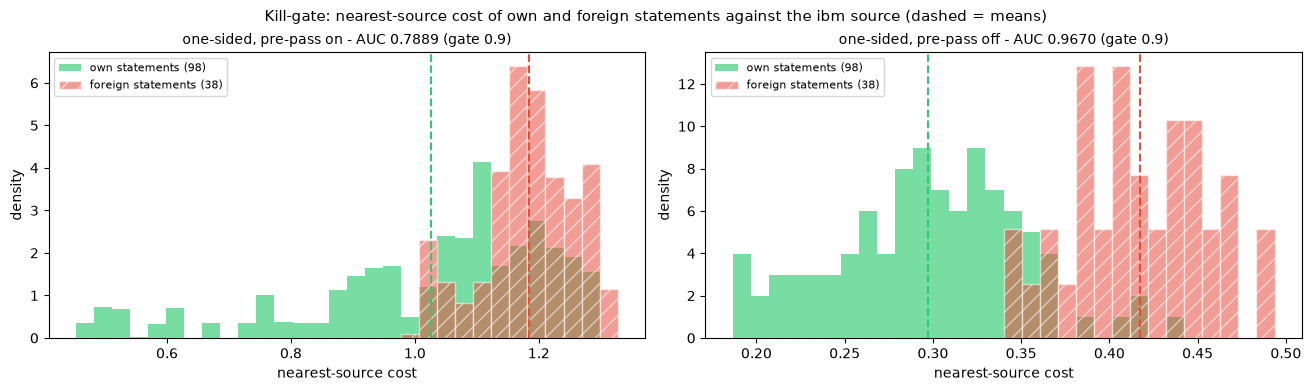

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
for ax, arm in zip(axes, ONE_SIDED):
    own_vals, foreign_vals = gate_pool(arm, LABELS)
    bins = np.linspace(min(own_vals.min(), foreign_vals.min()), max(own_vals.max(), foreign_vals.max()), 31)
    ax.hist(own_vals, bins=bins, density=True, color=C_GROUNDED, alpha=0.65, label=f"own statements ({N_OWN})")
    ax.hist(foreign_vals, bins=bins, density=True, color=C_UNGROUNDED, alpha=0.55, hatch="//", edgecolor="white",
            label=f"foreign statements ({int(PROSE.sum())})")
    ax.axvline(own_vals.mean(), color=C_GROUNDED, ls="--", lw=1.5)
    ax.axvline(foreign_vals.mean(), color=C_UNGROUNDED, ls="--", lw=1.5)
    ax.set_title(f"{ARMS[arm]} - AUC {GATE[arm]['auc']:.4f} (gate {GATE_AUC_MIN})", fontsize=10)
    ax.set_xlabel("nearest-source cost"); ax.set_ylabel("density"); ax.legend(fontsize=8)
fig.suptitle("Kill-gate: nearest-source cost of own and foreign statements against the ibm source (dashed = means)", fontsize=11)
plt.show()

**Reading** - under the configured rule the gate does not fire. The geometry carries a grounding signal on the raw embeddings, and a large part of that signal is absent under the pre-pass.

- **Pre-pass off** - AUC 0.9670 over 3724 pairs, above the 0.90 bar. Own statements read 0.2975 ± 0.0532 to their nearest source statement and foreign statements 0.4172 ± 0.0384; the gap between the means, 0.1197, is larger than the own spread
- **Pre-pass on** - AUC 0.7889, below the bar; this arm fails the gate and, under the configuration rule, is not used for the verdict. Own statements read 1.0264 ± 0.2023 and foreign statements 1.1844 ± 0.0754; the gap between the means, 0.1579, is smaller than the own spread
- **Not caused by the adversarial summaries** - with the own statements of the 7 gold-tier summaries only, the arms read 0.9836 (off) and 0.8223 (on); the pre-pass-on arm stays below 0.90
- **Not caused by the foreign-set rule** - with the 6 heading fragments included the arms read 0.9260 (off) and 0.7270 (on); each arm stays on the same side of the bar
- **Not measured here** - the pre-pass subtracts the pooled mean and then removes the top principal component, once per call. Which of the two steps reduces the separation was not decomposed
- **Consequence** - the verdict is read on the one-sided residual with the pre-pass off. Read on the pre-pass-on arm alone, the gate would have fired; the conclusions state this alternative reading. The kill-gate line of the record names no pre-pass setting, so which setting the gate reads is a decision of the campaign orchestrator

## Harness sanity check - the DEF-TRANS-8 reading

The record's motivating number must be reproduced before any arm is scored: 10 statements copied verbatim from
the source, `X = source[0::7][:10]`, through the shipped `compute_source_conditioned(X, X, source)` with the
default pre-pass, read `residual_a` 0.958 and `closeness_a` 0.322. The check passes when both readings round to
the registered values at 3 decimals. The exact plan is also read: the mass each statement keeps on its own
copy in the source is bounded by `n/m`.

In [11]:
X_V = E_S[0::EXTRACT_STRIDE][:EXTRACT_N]
shipped_on = compute_source_conditioned(X_V, X_V, E_S)                       # default: pre-pass on
shipped_off = compute_source_conditioned(X_V, X_V, E_S, anisotropy=False)

sanity_read = {"residual_a": shipped_on.residual_a, "closeness_a": shipped_on.closeness_a}
sanity_ok = all(round(sanity_read[key], SANITY_DECIMALS) == SANITY_TARGET[key] for key in SANITY_TARGET)

# mechanism: share of each statement's mass that the exact plan leaves on its own copy in the source
Xp_V, Sp_V = prepass(X_V, E_S)
plan = transport_plan(Xp_V, Sp_V)
own_copy = np.arange(EXTRACT_N) * EXTRACT_STRIDE
kept = plan[np.arange(EXTRACT_N), own_copy] * EXTRACT_N
mass_bound = EXTRACT_N / len(E_S)
nearest_pre = float(nearest_source_costs(Xp_V, Sp_V).mean())
nearest_raw = float(nearest_source_costs(X_V, E_S).mean())

st = Table(title="Harness sanity check - DEF-TRANS-8 on source[0::7][:10], shipped compute_source_conditioned",
           header_style="bold cyan")
for col in ("reading", "arm", "this notebook", "registered", "verdict"):
    st.add_column(col, justify="right" if col in ("this notebook", "registered") else "left")
for key in SANITY_TARGET:
    ok = round(sanity_read[key], SANITY_DECIMALS) == SANITY_TARGET[key]
    st.add_row(key, ARMS["bal_pre"], f"{sanity_read[key]:.6f}", f"{SANITY_TARGET[key]:.3f}",
               "[green]reproduced[/green]" if ok else "[red]DIFFERS[/red]")
st.add_row("residual_a", ARMS["bal_raw"], f"{shipped_off.residual_a:.6f}", "-", "reported")
st.add_row("closeness_a", ARMS["bal_raw"], f"{shipped_off.closeness_a:.6f}", "-", "reported")
st.add_row("nearest-source mean cost", ARMS["os_pre"], f"{nearest_pre:.6f}", "0.0001 (defect repro line)", "reported")
st.add_row("nearest-source mean cost", ARMS["os_raw"], f"{nearest_raw:.6f}", "0.0001 (defect repro line)", "reported")
st.add_row("mass kept on the own copy, max over 10", ARMS["bal_pre"], f"{kept.max():.6f}", f"bound n/m = {mass_bound:.6f}", "reported")
st.add_row("mass kept on the own copy, mean over 10", ARMS["bal_pre"], f"{kept.mean():.6f}", f"bound n/m = {mass_bound:.6f}", "reported")
sanity_line = (f"SANITY CHECK: {'PASSED' if sanity_ok else 'FAILED'} - residual_a {sanity_read['residual_a']:.3f}, "
               f"closeness_a {sanity_read['closeness_a']:.3f} (balanced, pre-pass on)")
console.print(Group(st, f"[bold {'green' if sanity_ok else 'red'}]{sanity_line}[/]"))

                          Harness sanity check - DEF-TRANS-8 on source[0::7][:10], shipped compute_source_conditioned                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ reading                                 ┃ arm                                     ┃ this notebook ┃                 registered ┃ verdict    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ residual_a                              │ balanced (shipped default), pre-pass on │      0.958211 │                      0.958 │ reproduced │
│ closeness_a                             │ balanced (shipped default), pre-pass on │      0.322442 │                      0.322 │ reproduced │
│ residual_a                              │ balanced (shipped), pre-pass off        │      0.517224 │                          - │ reported   │
│ closeness_a                             │ balanced (shipped), pre-pass off        │      0.634268 │                          - │ reported   │
│ nearest-source mean cost                │ one-sided, pre-pass on                  │      0.000152 │ 0.0001 (defect repro line) │ reported   │
│ nearest-source mean cost                │ one-sided, pre-pass off                 │      0.000118 │ 0.0001 (defect repro line) │ reported   │
│ mass kept on the own copy, max over 10  │ balanced (shipped default), pre-pass on │      0.142857 │       bound n/m = 0.142857 │ reported   │
│ mass kept on the own copy, mean over 10 │ balanced (shipped default), pre-pass on │      0.142857 │       bound n/m = 0.142857 │ reported   │
└─────────────────────────────────────────┴─────────────────────────────────────────┴───────────────┴────────────────────────────┴────────────┘
SANITY CHECK: PASSED - residual_a 0.958, closeness_a 0.322 (balanced, pre-pass on)

**Reading** - the harness reproduces `DEF-TRANS-8`.

- **Reproduced** - `residual_a` 0.958211 and `closeness_a` 0.322442 with the default pre-pass, against the registered 0.958 and 0.322
- **Mechanism read from the plan** - each of the 10 copied statements keeps 0.142857 of its mass on its own copy, which is the bound `n/m` = 10/70; the exact plan ships the rest of the mass to other source statements
- **Present without the pre-pass** - on the raw embeddings the balanced residual reads 0.517224 (closeness 0.634268), so the defect belongs to the balanced source marginal and not to the pre-pass
- **Nearest-source cost** - 0.000152 with the pre-pass on and 0.000118 with it off, against the 0.0001 of the defect's repro line; the cost of a statement to its own copy is zero up to float32 rounding

## Registered experiment

All four arms are scored on the same documents and the same doses. Three readings feed the acceptance bar:

- **verbatim extract** - closeness $1 - r/\sqrt{2}$ of `source[0::7][:10]`; the six other offsets of the same stride are reported beside it
- **insertion doses** - per (document, seed), `k` in 0..4 foreign statements appended; Spearman(`k`, residual) per trajectory
- **deletion doses** - per (document, seed), `k` in 1..4 own statements removed; |residual change| against the mean one-insertion effect

In [12]:
VERB = score(X_V)
VERBATIM = {arm: {"residual": VERB[arm], "closeness": closeness(VERB[arm])} for arm in ARMS}

# the six other offsets of the same stride: ten statements each, also copied verbatim
offset_closeness = {arm: [] for arm in ARMS}
for offset in range(EXTRACT_STRIDE):
    sc = VERB if offset == 0 else score(E_S[offset::EXTRACT_STRIDE][:EXTRACT_N])
    for arm in ARMS:
        offset_closeness[arm].append(closeness(sc[arm]))
for arm in ARMS:
    VERBATIM[arm]["min_closeness_7_offsets"] = min(offset_closeness[arm])
    VERBATIM[arm]["max_closeness_7_offsets"] = max(offset_closeness[arm])

vt = Table(title="Verbatim extract source[0::7][:10] - 10 statements copied from the 70-statement source", header_style="bold cyan")
for col in ("arm", "residual", "closeness", f"bar >= {BAR_CLOSENESS}", "closeness over the 7 offsets, min / max"):
    vt.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    v = VERBATIM[arm]
    vt.add_row(ARMS[arm], f"{v['residual']:.6f}", f"{v['closeness']:.6f}",
               "[green]met[/green]" if v["closeness"] >= BAR_CLOSENESS else "[red]not met[/red]",
               f"{v['min_closeness_7_offsets']:.6f} / {v['max_closeness_7_offsets']:.6f}")
console.print(vt)

                  Verbatim extract source[0::7][:10] - 10 statements copied from the 70-statement source                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                                     ┃ residual ┃ closeness ┃ bar >= 0.99 ┃ closeness over the 7 offsets, min / max ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ one-sided, pre-pass on                  │ 0.000152 │  0.999892 │         met │                     0.999820 / 0.999931 │
│ one-sided, pre-pass off                 │ 0.000118 │  0.999917 │         met │                     0.999867 / 0.999941 │
│ balanced (shipped default), pre-pass on │ 0.958211 │  0.322442 │     not met │                     0.319219 / 0.434458 │
│ balanced (shipped), pre-pass off        │ 0.517224 │  0.634268 │     not met │                     0.606019 / 0.758223 │
└─────────────────────────────────────────┴──────────┴───────────┴─────────────┴─────────────────────────────────────────┘

### Insertion and deletion doses

Foreign statements are appended and own statements are removed. Both residuals depend on the set of statements
and not on their order, so the position of an insertion is not a factor. The `k = 0` document is the summary
itself and is shared by all 14 seeds of that document.

In [13]:
rng = np.random.default_rng(SEED)
INSERT_DRAWS = {label: [rng.choice(len(E_F), size=max(INSERT_KS), replace=False) for _ in range(N_SEEDS)] for label in LABELS}
DELETE_ORDERS = {label: [rng.permutation(len(E[label])) for _ in range(N_SEEDS)] for label in LABELS}


def insertion_dose(label: str, seed: int, k: int) -> np.ndarray:
    '''The summary with the first k foreign statements of this seed's draw appended'''
    return np.vstack([E[label], E_F[INSERT_DRAWS[label][seed][:k]]])


def deletion_dose(label: str, seed: int, k: int) -> np.ndarray:
    '''The summary with the first k statements of this seed's order removed, order kept'''
    return np.delete(E[label], DELETE_ORDERS[label][seed][:k], axis=0)


BASE = {label: score(E[label]) for label in LABELS}   # k = 0
INS = {arm: np.zeros((len(LABELS), N_SEEDS, len(INSERT_KS))) for arm in ARMS}            # residual
DEL = {arm: np.full((len(LABELS), N_SEEDS, len(DELETE_KS)), np.nan) for arm in ARMS}     # residual change; NaN = no such dose

jobs = [(di, label, seed) for di, label in enumerate(LABELS) for seed in range(N_SEEDS)]
for di, label, seed in tqdm(jobs, desc="doses (document, seed)", mininterval=2.0):
    for ki, k in enumerate(INSERT_KS):
        sc = BASE[label] if k == 0 else score(insertion_dose(label, seed, k))
        for arm in ARMS:
            INS[arm][di, seed, ki] = sc[arm]
    for ki in [ki for ki, k in enumerate(DELETE_KS) if len(E[label]) - k >= 1]:
        sc = score(deletion_dose(label, seed, DELETE_KS[ki]))
        for arm in ARMS:
            DEL[arm][di, seed, ki] = sc[arm] - BASE[label][arm]

n_insert_scored = len(jobs) * (len(INSERT_KS) - 1)
n_delete_cases = int((~np.isnan(DEL["os_pre"])).sum())

doses (document, seed):   0%|          | 0/154 [00:00<?, ?it/s]

doses (document, seed):  16%|█▌        | 24/154 [00:02<00:11, 11.62it/s]

doses (document, seed):  35%|███▌      | 54/154 [00:04<00:07, 13.45it/s]

doses (document, seed):  55%|█████▍    | 84/154 [00:06<00:04, 14.06it/s]

doses (document, seed):  74%|███████▍  | 114/154 [00:08<00:02, 14.25it/s]

doses (document, seed): 100%|██████████| 154/154 [00:09<00:00, 15.57it/s]

In [14]:
def insertion_readings(arm: str) -> dict:
    '''Dose-response of one arm under foreign insertions'''
    r = INS[arm]
    ks = np.array(INSERT_KS)
    traj = np.array([[spearmanr(ks, r[di, seed]).statistic for seed in range(N_SEEDS)] for di in range(len(LABELS))])
    per_doc = traj.mean(1)                                        # the bar's per-document Spearman
    pooled = [spearmanr(np.tile(ks, N_SEEDS), r[di].ravel()).statistic for di in range(len(LABELS))]
    curve = [spearmanr(ks, r[di].mean(0)).statistic for di in range(len(LABELS))]
    return {
        "per_document_spearman": {label: float(per_doc[di]) for di, label in enumerate(LABELS)},
        "median_per_document_spearman": float(np.median(per_doc)),
        "min_per_document_spearman": float(per_doc.min()),
        "monotone_trajectory_share": float((traj > 1 - 1e-12).mean()),
        "median_spearman_pooled_points": float(np.median(pooled)),      # sensitivity: 70 points per document, ties in k
        "median_spearman_seed_mean_curve": float(np.median(curve)),     # sensitivity: 5 points, seeds averaged first
        "one_insertion_effect": float((r[:, :, 1] - r[:, :, 0]).mean()),
        "mean_residual_by_k": [float(v) for v in r.mean((0, 1))],
    }


def deletion_readings(arm: str, one_insertion_effect: float) -> dict:
    '''Residual change of one arm under deletions, against its own one-insertion effect'''
    d = DEL[arm]
    exists = ~np.isnan(d)
    median_abs = float(np.median(np.abs(d[exists])))
    by_k = [float(np.median(np.abs(d[:, :, ki][exists[:, :, ki]]))) for ki in range(len(DELETE_KS))]
    dosed = exists.any(axis=(1, 2))                                   # documents with at least one deletion dose
    matched_effect = float((INS[arm][dosed, :, 1] - INS[arm][dosed, :, 0]).mean())
    positive = one_insertion_effect > 0
    return {
        "median_abs_delta": median_abs,
        "ratio_to_one_insertion": median_abs / one_insertion_effect if positive else None,          # the bar reading
        "mean_signed_delta": float(d[exists].mean()),
        "mean_signed_delta_share": float(d[exists].mean()) / one_insertion_effect if positive else None,
        "median_abs_delta_by_k": by_k,
        "ratio_k1_only": by_k[0] / one_insertion_effect if positive else None,                      # sensitivity: one deletion
        "ratio_matched_documents": median_abs / matched_effect if matched_effect > 0 else None,     # sensitivity: same documents
        "n_documents_with_deletion_doses": int(dosed.sum()),
        "p90_abs_delta": float(np.percentile(np.abs(d[exists]), 90)),
    }


def share_text(value) -> str:
    '''A ratio as a percentage; None means the one-insertion effect of that arm is not positive'''
    return "undefined" if value is None else f"{value:.1%}"


# ceiling of the pooled-points reading: 14 seeds share each k, so a perfectly ordered response reads below 1
ideal = np.array([[0.0] + [k + (seed + 1) * 1e-3 for k in INSERT_KS[1:]] for seed in range(N_SEEDS)])
POOLED_CEILING = float(spearmanr(np.tile(INSERT_KS, N_SEEDS), ideal.ravel()).statistic)


INSERTION = {arm: insertion_readings(arm) for arm in ARMS}
DELETION = {arm: deletion_readings(arm, INSERTION[arm]["one_insertion_effect"]) for arm in ARMS}

it = Table(title=f"Insertion doses - {len(LABELS)} documents x {N_SEEDS} seeds, k in {INSERT_KS} ({n_insert_scored} dosed documents)",
           header_style="bold cyan")
for col in ("arm", "mean residual at k = 0, 1, 2, 3, 4", "one-insertion effect", "median per-document Spearman (bar)",
            "min per-document", "monotone trajectories", "median Spearman, pooled points", "median Spearman, seed-mean curve"):
    it.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    r = INSERTION[arm]
    it.add_row(ARMS[arm], "  ".join(f"{v:.4f}" for v in r["mean_residual_by_k"]), f"{r['one_insertion_effect']:+.5f}",
               f"{r['median_per_document_spearman']:.4f}", f"{r['min_per_document_spearman']:.4f}",
               f"{r['monotone_trajectory_share']:.1%}", f"{r['median_spearman_pooled_points']:.4f}",
               f"{r['median_spearman_seed_mean_curve']:.4f}")

dt = Table(title=f"Deletion doses - k in {DELETE_KS}, {n_delete_cases} existing (document, seed, k) cases", header_style="bold cyan")
for col in ("arm", "median |delta| (numerator)", "one insertion (denominator)", "ratio (bar)",
            "ratio, k = 1 only", "ratio, same documents", "median |delta| at k = 1, 2, 3, 4", "p90 |delta|",
            "mean signed delta", "signed delta / one insertion"):
    dt.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    d, r = DELETION[arm], INSERTION[arm]
    dt.add_row(ARMS[arm], f"{d['median_abs_delta']:.5f}", f"{r['one_insertion_effect']:+.5f}", share_text(d["ratio_to_one_insertion"]),
               share_text(d["ratio_k1_only"]), share_text(d["ratio_matched_documents"]),
               "  ".join(f"{v:.5f}" for v in d["median_abs_delta_by_k"]), f"{d['p90_abs_delta']:.5f}",
               f"{d['mean_signed_delta']:+.5f}", share_text(d["mean_signed_delta_share"]))

pt = Table(title="Per-document Spearman(k insertions, residual), mean over 14 seeds", header_style="bold cyan")
pt.add_column("document"); pt.add_column("tier"); pt.add_column("statements", justify="right")
for arm in ARMS:
    pt.add_column(ARMS[arm], justify="right")
for label in LABELS:
    pt.add_row(label, TIER[label], str(len(E[label])),
               *[f"{INSERTION[arm]['per_document_spearman'][label]:.4f}" for arm in ARMS], style=TIER_COLOR[TIER[label]])
console.print(Group(
    it,
    f"ceiling of the pooled-points reading when every dose level is perfectly ordered: {POOLED_CEILING:.4f}",
    dt,
    f"'ratio, same documents' divides by the one-insertion effect of the {DELETION['os_raw']['n_documents_with_deletion_doses']} documents "
    "that have deletion doses (adv2-a has one statement and no deletion dose)",
    pt,
))

                                               Insertion doses - 11 documents x 14 seeds, k in (0, 1, 2, 3, 4) (616 dosed documents)                                                
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃                      ┃ mean residual at k = ┃                      ┃  median per-document ┃                  ┃             monotone ┃     median Spearman, ┃    median Spearman, ┃
┃ arm                  ┃        0, 1, 2, 3, 4 ┃ one-insertion effect ┃       Spearman (bar) ┃ min per-document ┃         trajectories ┃        pooled points ┃     seed-mean curve ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ one-sided, pre-pass  │       1.0599  1.0674 │             +0.00749 │               0.9643 │          -0.4786 │                65.6% │               0.8674 │              1.0000 │
│ on                   │       1.0764  1.0865 │                      │                      │                  │                      │                      │                     │
│                      │               1.0958 │                      │                      │                  │                      │                      │                     │
│ one-sided, pre-pass  │       0.3027  0.3180 │             +0.01529 │               1.0000 │           0.9214 │                93.5% │               0.9492 │              1.0000 │
│ off                  │       0.3276  0.3353 │                      │                      │                  │                      │                      │                     │
│                      │               0.3416 │                      │                      │                  │                      │                      │                     │
│ balanced (shipped    │       1.2865  1.2733 │             -0.01328 │              -0.8429 │          -0.9714 │                 0.0% │              -0.7590 │             -1.0000 │
│ default), pre-pass   │       1.2681  1.2653 │                      │                      │                  │                      │                      │                     │
│ on                   │               1.2640 │                      │                      │                  │                      │                      │                     │
│ balanced (shipped),  │       0.7252  0.7208 │             -0.00441 │              -0.2571 │          -1.0000 │                 3.2% │              -0.3253 │             -0.8000 │
│ pre-pass off         │       0.7193  0.7183 │                      │                      │                  │                      │                      │                     │
│                      │               0.7181 │                      │                      │                  │                      │                      │                     │
└──────────────────────┴──────────────────────┴──────────────────────┴──────────────────────┴──────────────────┴──────────────────────┴──────────────────────┴─────────────────────┘
ceiling of the pooled-points reading when every dose level is perfectly ordered: 0.9838
                                                     Deletion doses - k in (1, 2, 3, 4), 532 existing (document, seed, k) cases                                                     
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃                  ┃                  ┃                  ┃             ┃                  ┃                  ┃   median |delta| ┃             ┃                 ┃                  ┃
┃                  ┃   median |delta| ┃    one insertion ┃             ┃     ratio, k = 1 ┃      ratio, same ┃ 

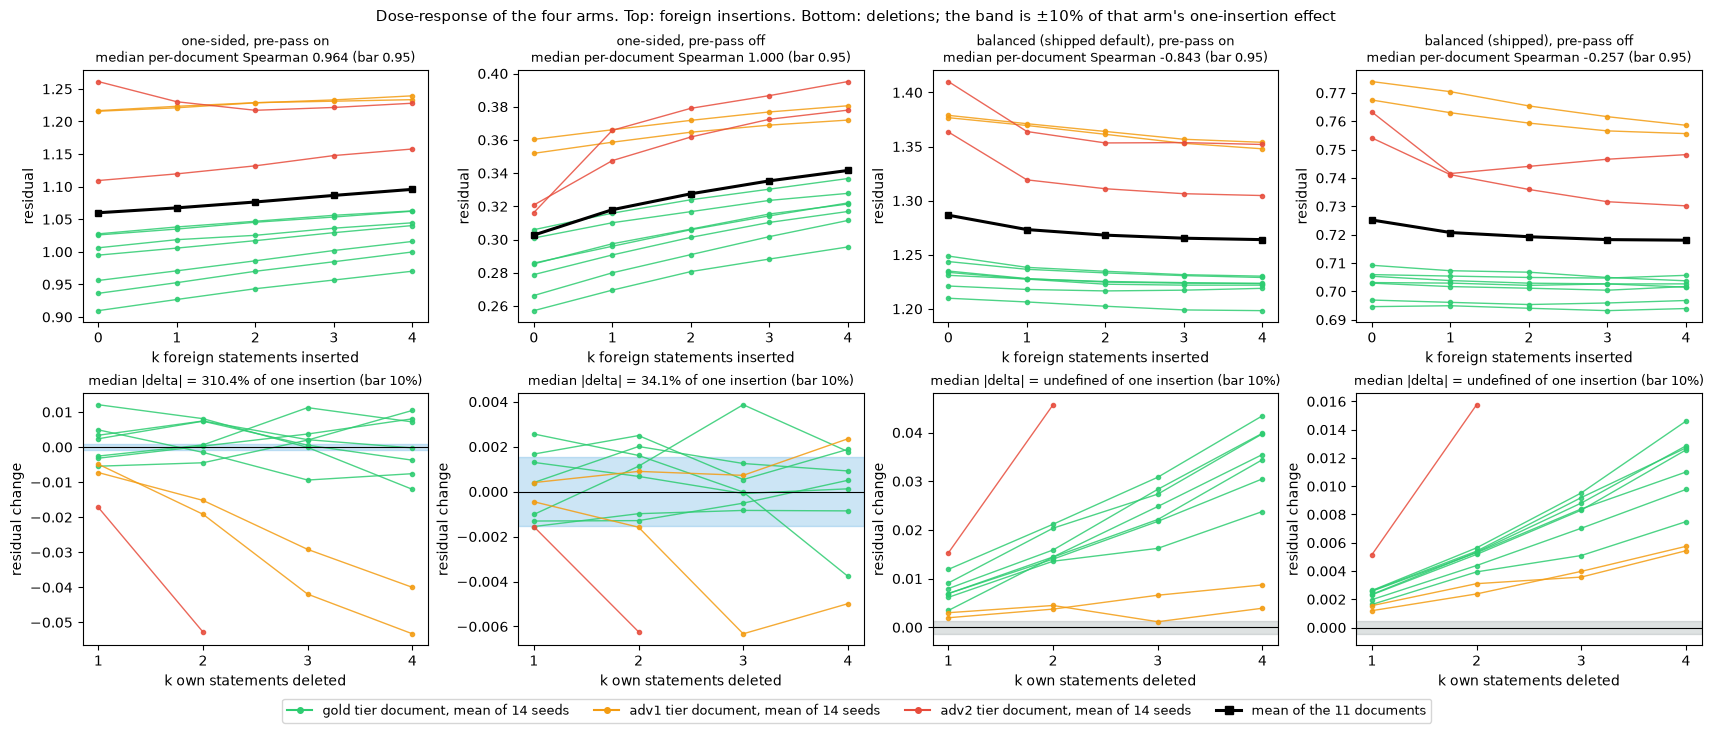

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), constrained_layout=True)
for col, arm in enumerate(ARMS):
    top, bottom = axes[0, col], axes[1, col]
    for di, label in enumerate(LABELS):
        colour = TIER_COLOR[TIER[label]]
        top.plot(INSERT_KS, INS[arm][di].mean(0), color=colour, lw=1, alpha=0.85, marker="o", ms=3)
        bottom.plot(DELETE_KS, np.nanmean(DEL[arm][di], axis=0), color=colour, lw=1, alpha=0.85, marker="o", ms=3)
    top.plot(INSERT_KS, INS[arm].mean((0, 1)), color="black", lw=2.2, marker="s", ms=5)
    top.set_title(f"{ARMS[arm]}\nmedian per-document Spearman {INSERTION[arm]['median_per_document_spearman']:.3f} (bar {BAR_SPEARMAN})", fontsize=9)
    top.set_xlabel("k foreign statements inserted"); top.set_ylabel("residual"); top.set_xticks(INSERT_KS)
    effect = INSERTION[arm]["one_insertion_effect"]
    bottom.axhspan(-BAR_DELETION_RATIO * abs(effect), BAR_DELETION_RATIO * abs(effect), color=ARM_COLOR[arm], alpha=0.25)
    bottom.axhline(0, color="black", lw=0.8)
    ratio = DELETION[arm]["ratio_to_one_insertion"]
    bottom.set_title(f"median |delta| = {share_text(ratio)} of one insertion (bar {BAR_DELETION_RATIO:.0%})", fontsize=9)
    bottom.set_xlabel("k own statements deleted"); bottom.set_ylabel("residual change"); bottom.set_xticks(DELETE_KS)
handles = [Line2D([], [], color=TIER_COLOR[t], marker="o", ms=4, label=f"{t} tier document, mean of {N_SEEDS} seeds") for t in TIERS]
handles.append(Line2D([], [], color="black", lw=2.2, marker="s", label="mean of the 11 documents"))
fig.legend(handles=handles, loc="outside lower center", ncols=4, fontsize=9)
fig.suptitle("Dose-response of the four arms. Top: foreign insertions. Bottom: deletions; the band is ±10% of that arm's one-insertion effect", fontsize=11)
plt.show()

### Acceptance bar

The record's bar, applied to each arm separately: verbatim-extract closeness at or above 0.99 AND median
per-document Spearman at or above 0.95 AND the deletion ratio at or below 10%. The balanced arms are scored on
the same doses and are the baseline the record names. The table also shows the pooled-points reading of the
Spearman condition, which is not the configured bar rule.

In [16]:
BAR = {}
for arm in ARMS:
    ratio = DELETION[arm]["ratio_to_one_insertion"]
    checks = {
        "verbatim_closeness": (VERBATIM[arm]["closeness"], VERBATIM[arm]["closeness"] >= BAR_CLOSENESS),
        "median_per_document_spearman": (INSERTION[arm]["median_per_document_spearman"],
                                         INSERTION[arm]["median_per_document_spearman"] >= BAR_SPEARMAN),
        "deletion_ratio": (ratio, ratio is not None and ratio <= BAR_DELETION_RATIO),
    }
    BAR[arm] = {key: value for key, (value, _) in checks.items()}
    BAR[arm].update({f"{key}_met": bool(ok) for key, (_, ok) in checks.items()})
    BAR[arm]["met"] = all(ok for _, ok in checks.values())


def mark(ok: bool) -> str:
    '''Console label of one bar condition'''
    return "[green]met[/green]" if ok else "[red]not met[/red]"


bt = Table(title="Acceptance bar per arm - the record's three conditions", header_style="bold cyan")
for col in ("arm", f"verbatim closeness >= {BAR_CLOSENESS}", f"median per-document Spearman >= {BAR_SPEARMAN}",
            "pooled-points Spearman (not the bar rule)", f"deletion ratio <= {BAR_DELETION_RATIO:.0%}", "bar"):
    bt.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    b = BAR[arm]
    bt.add_row(ARMS[arm], f"{b['verbatim_closeness']:.4f} {mark(b['verbatim_closeness_met'])}",
               f"{b['median_per_document_spearman']:.4f} {mark(b['median_per_document_spearman_met'])}",
               f"{INSERTION[arm]['median_spearman_pooled_points']:.4f}",
               f"{share_text(b['deletion_ratio'])} {mark(b['deletion_ratio_met'])}", mark(b["met"]))
console.print(bt)

                                                               Acceptance bar per arm - the record's three conditions                                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃                                      ┃                            ┃                                      ┃ pooled-points Spearman (not the bar ┃                       ┃         ┃
┃ arm                                  ┃ verbatim closeness >= 0.99 ┃ median per-document Spearman >= 0.95 ┃                               rule) ┃ deletion ratio <= 10% ┃     bar ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ one-sided, pre-pass on               │                 0.9999 met │                           0.9643 met │                              0.8674 │        310.4% not met │ not met │
│ one-sided, pre-pass off              │                 0.9999 met │                           1.0000 met │                              0.9492 │         34.1% not met │ not met │
│ balanced (shipped default), pre-pass │             0.3224 not met │                      -0.8429 not met │                             -0.7590 │     undefined not met │ not met │
│ on                                   │                            │                                      │                                     │                       │         │
│ balanced (shipped), pre-pass off     │             0.6343 not met │                      -0.2571 not met │                             -0.3253 │     undefined not met │ not met │
└──────────────────────────────────────┴────────────────────────────┴──────────────────────────────────────┴─────────────────────────────────────┴───────────────────────┴─────────┘

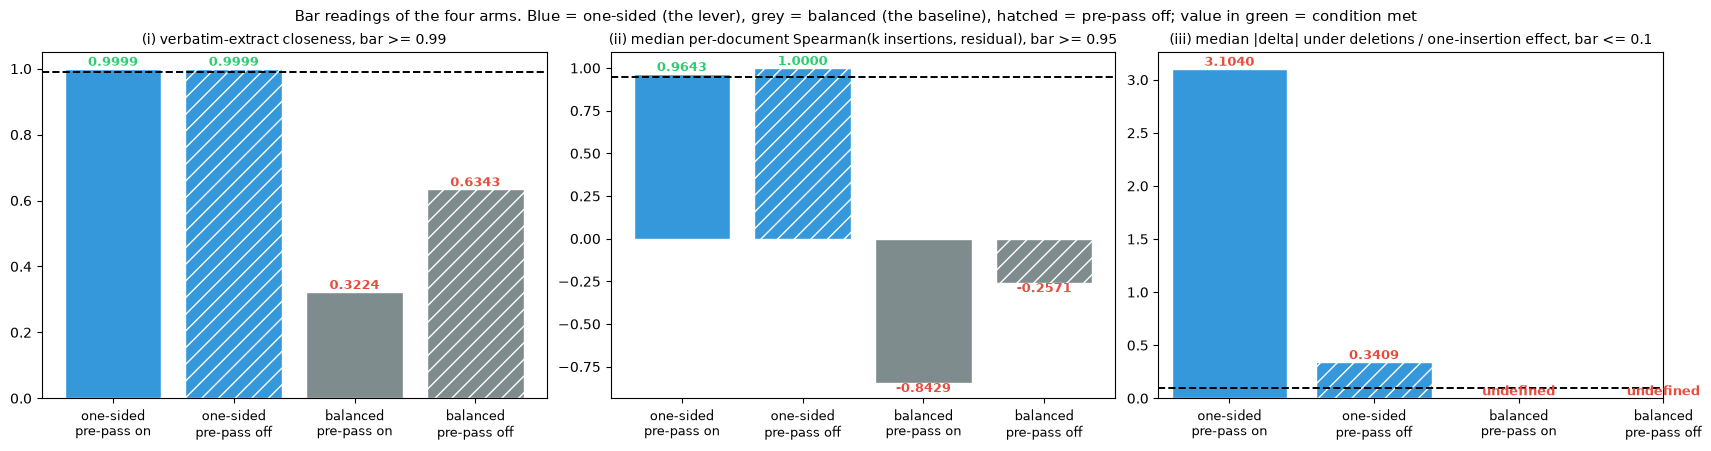

In [17]:
def bar_panel(ax, values: list, threshold: float, title: str, above: bool) -> None:
    '''One bar per arm with the acceptance threshold; the green side of the line is the passing side'''
    xs = np.arange(len(ARMS))
    bars = ax.bar(xs, values, color=[ARM_COLOR[a] for a in ARMS], hatch=[ARM_HATCH[a] for a in ARMS], edgecolor="white")
    ax.axhline(threshold, color="black", ls="--", lw=1.4)
    for x, v in zip(xs, values):
        ok = v >= threshold if above else v <= threshold
        text, y = ("undefined", 0.0) if np.isnan(v) else (f"{v:.4f}", v)
        ax.annotate(text, (x, y), ha="center", va="bottom" if y >= 0 else "top", fontsize=9,
                    color=C_GROUNDED if ok else C_UNGROUNDED, fontweight="bold")
    ax.set_xticks(xs); ax.set_xticklabels([ARM_TICK[a] for a in ARMS], fontsize=9)
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True)
bar_panel(axes[0], [BAR[a]["verbatim_closeness"] for a in ARMS], BAR_CLOSENESS,
          f"(i) verbatim-extract closeness, bar >= {BAR_CLOSENESS}", above=True)
bar_panel(axes[1], [BAR[a]["median_per_document_spearman"] for a in ARMS], BAR_SPEARMAN,
          f"(ii) median per-document Spearman(k insertions, residual), bar >= {BAR_SPEARMAN}", above=True)
bar_panel(axes[2], [np.nan if BAR[a]["deletion_ratio"] is None else BAR[a]["deletion_ratio"] for a in ARMS], BAR_DELETION_RATIO,
          f"(iii) median |delta| under deletions / one-insertion effect, bar <= {BAR_DELETION_RATIO}", above=False)
fig.suptitle("Bar readings of the four arms. Blue = one-sided (the lever), grey = balanced (the baseline), hatched = pre-pass off; "
             "value in green = condition met", fontsize=11)
plt.show()

**Reading** - neither one-sided arm meets the bar. Condition (i) is met and cannot fail for this residual, condition (ii) is met under the configured reading rule and not under the pooled-points reading, condition (iii) is not met.

- **(i) Verbatim extract, met by construction** - closeness 0.9999 on both one-sided arms, against 0.3224 (balanced, pre-pass on) and 0.6343 (balanced, pre-pass off). Over the 7 offsets of the stride the lowest one-sided closeness is 0.999820. Every row of the extract is a row of the source, so its nearest-source cost is zero up to float32 rounding in any residual with the source marginal released. The condition shows that the `n/m` bound is absent; it does not test the residual on text that differs from the source
- **(ii) Insertion dose-response, met under the per-trajectory reading** - pre-pass off: median per-document Spearman 1.0000, lowest document 0.9214 (`adv2-a`, one statement), 93.5% of the 11 x 14 trajectories strictly increasing. Pre-pass on: median 0.9643, lowest document -0.4786 (`adv2-a`), 65.6% strictly increasing
- **(ii) under the pooled-points reading** - with the 70 points of a document in one Spearman the medians are 0.9492 (pre-pass off) and 0.8674 (pre-pass on), both below 0.95; a perfectly ordered response reads 0.9838 there, because 14 seeds share each `k`. With the seeds averaged first, both arms read 1.0000. The record does not say how seeds enter, so condition (ii) is met under two of the three readings and not met under one. The verdict does not depend on this rule, because (iii) is not met under any of the three denominators
- **The balanced baseline responds with the opposite sign** - the shipped residual falls when foreign statements are added: 1.2865 → 1.2640 over `k` = 0..4 with the pre-pass on (median Spearman -0.8429) and 0.7252 → 0.7181 with it off (-0.2571). Each added statement raises `n/m`, so the plan may leave more mass on near source statements
- **(iii) Deletions, not met** - the median |residual change| is 34.1% of one insertion with the pre-pass off and 310.4% with it on, against a bar of 10%. The choice of denominator does not change the side of the bar: one deletion only reads 23.1% and 176.2%; the same 10 documents in numerator and denominator read 43.9% and 205.1%
- **Not flatter than the baseline under deletions** - on the same deletion doses the median |residual change| of the one-sided residual is 0.00521 against 0.00504 for the balanced residual (pre-pass off) and 0.02326 against 0.01548 (pre-pass on). With the pre-pass off the 90th percentile is 0.01523 against a one-insertion effect of 0.01529: one deletion case in ten moves the one-sided residual by 0.01523 or more
- **Signed change under deletions** - with the pre-pass off the mean signed change of the one-sided residual is -0.00011, which is -0.7% of one insertion: the rises and the falls are of equal size on average. The balanced residual rises under deletions by +0.00622 (pre-pass off) and +0.01789 (pre-pass on). With the pre-pass on, the one-sided residual falls by 0.00630 on average, 84.0% of one insertion
- **Mechanism of the failed condition** - the one-sided residual is the mean of per-statement costs. Removing statement `i` from a document of `n` statements changes it by $(r - c_i)/(n-1)$; adding a foreign statement `f` changes it by $(c_f - r)/(n+1)$. The ratio of the two is set by the spread of the own costs against the gap to the foreign costs, which the kill-gate table reads as 0.0532 against 0.1197 on the raw embeddings. A 10% ratio needs a spread close to one tenth of the gap

### Also reported, no bar - tier readings and the model-graded residual

Two readings the record asks for without a bar. The tier reading is each summary's own residual by tier: gold
(7 faithful summaries, the anchor included), adv1 (information loss) and adv2 (information noise). The second
reading is the rank agreement with the model-graded residual `grounding_residual(R, entail)`, recomputed with the
shipped function from the reranker and NLI signals that `E12-H69` stored. The per-statement form of the same
comparison uses the 98 statements: nearest-source cost against the ungrounded mass $(1 - e_i)(1 - \max_j R_{ij})$.

In [18]:
signals = np.load(GROUNDING_NPZ)
MODEL_GRD = {label: grounding_residual(signals[f"R__{label}"], signals[f"ent__{label}"]) for label in LABELS}
ungrounded_mass = np.concatenate([(1.0 - signals[f"ent__{label}"].astype(float)) * (1.0 - signals[f"R__{label}"].max(1).astype(float))
                                  for label in LABELS])
statement_cost = {
    "os_pre": np.concatenate([nearest_source_costs(*prepass(E[label], E_S)) for label in LABELS]),
    "os_raw": np.concatenate([own_raw[label] for label in LABELS]),
}

model_vec = np.array([MODEL_GRD[label] for label in LABELS])
NOBAR = {}
for arm in ARMS:
    res = {label: BASE[label][arm] for label in LABELS}
    gold = [res[l] for l in LABELS if TIER[l] == "gold"]
    adv2_floor = min(res[l] for l in LABELS if TIER[l] == "adv2")
    NOBAR[arm] = {
        "residual": res,
        "tier_mean": {t: float(np.mean([res[l] for l in LABELS if TIER[l] == t])) for t in TIERS},
        "gold_at_or_above_lowest_adv2": int(sum(1 for g in gold if g >= adv2_floor)),
        "spearman_vs_model_graded_documents": float(spearmanr([res[l] for l in LABELS], model_vec).statistic),
    }
for arm in ONE_SIDED:
    NOBAR[arm]["spearman_vs_ungrounded_mass_statements"] = float(spearmanr(statement_cost[arm], ungrounded_mass).statistic)

tt = Table(title="Residual of the 11 summaries (k = 0) by arm, with the model-graded residual", header_style="bold cyan")
tt.add_column("document"); tt.add_column("tier")
for arm in ARMS:
    tt.add_column(ARMS[arm], justify="right")
tt.add_column("model-graded (reranker x NLI)", justify="right")
for label in LABELS:
    tt.add_row(label, TIER[label], *[f"{NOBAR[arm]['residual'][label]:.4f}" for arm in ARMS], f"{MODEL_GRD[label]:.4f}",
               style=TIER_COLOR[TIER[label]])
model_tier = {t: float(np.mean([MODEL_GRD[l] for l in LABELS if TIER[l] == t])) for t in TIERS}
for t in TIERS:
    tt.add_row(f"mean, {t} tier", t, *[f"{NOBAR[arm]['tier_mean'][t]:.4f}" for arm in ARMS], f"{model_tier[t]:.4f}", style="bold")

rt = Table(title="Rank agreement with the model-graded residual - no bar", header_style="bold cyan")
for col in ("arm", "Spearman over the 11 documents", f"Spearman over the {N_OWN} statements",
            "gold-tier documents at or above the lowest adv2 (of 7)"):
    rt.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    n = NOBAR[arm]
    per_statement = f"{n['spearman_vs_ungrounded_mass_statements']:+.4f}" if arm in ONE_SIDED else "no per-statement form"
    rt.add_row(ARMS[arm], f"{n['spearman_vs_model_graded_documents']:+.4f}", per_statement, str(n["gold_at_or_above_lowest_adv2"]))
console.print(Group(tt, rt))

                                                    Residual of the 11 summaries (k = 0) by arm, with the model-graded residual                                                     
┏━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                 ┃      ┃                        ┃                         ┃       balanced (shipped default), ┃                                  ┃                               ┃
┃ document        ┃ tier ┃ one-sided, pre-pass on ┃ one-sided, pre-pass off ┃                       pre-pass on ┃ balanced (shipped), pre-pass off ┃ model-graded (reranker x NLI) ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold            │ gold │                 0.9949 │                  0.2858 │                            1.2349 │                           0.7031 │                        0.0017 │
│ gold-2          │ gold │                 0.9097 │                  0.2571 │                            1.2098 │                           0.6946 │                        0.0063 │
│ v1              │ gold │                 0.9363 │                  0.2789 │                            1.2211 │                           0.7059 │                        0.0972 │
│ v2              │ gold │                 1.0062 │                  0.2853 │                            1.2337 │                           0.7029 │                        0.0372 │
│ opus            │ gold │                 1.0258 │                  0.3059 │                            1.2437 │                           0.7053 │                        0.0456 │
│ sonnet          │ gold │                 0.9560 │                  0.2663 │                            1.2488 │                           0.7092 │                        0.0072 │
│ haiku           │ gold │                 1.0275 │                  0.3009 │                            1.2310 │                           0.6970 │                        0.1177 │
│ adv1-a          │ adv1 │                 1.2157 │                  0.3603 │                            1.3788 │                           0.7675 │                        0.3390 │
│ adv1-b          │ adv1 │                 1.2166 │                  0.3519 │                            1.3767 │                           0.7740 │                        0.2464 │
│ adv2-a          │ adv2 │                 1.2612 │                  0.3162 │                            1.4100 │                           0.7632 │                        0.0074 │
│ adv2-b          │ adv2 │                 1.1094 │                  0.3208 │                            1.3634 │                           0.7541 │                        0.0016 │
│ mean, gold tier │ gold │                 0.9795 │                  0.2829 │                            1.2318 │                           0.7026 │                        0.0447 │
│ mean, adv1 tier │ adv1 │                 1.2161 │                  0.3561 │                            1.3777 │                           0.7707 │                        0.2927 │
│ mean, adv2 tier │ adv2 │                 1.1853 │                  0.3185 │                            1.3867 │                           0.7587 │                        0.0045 │
└─────────────────┴──────┴────────────────────────┴─────────────────────────┴───────────────────────────────────┴──────────────────────────────────┴───────────────────────────────┘
                                                        Rank agreement with the model-graded residual - no bar                                                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                                     ┃ 

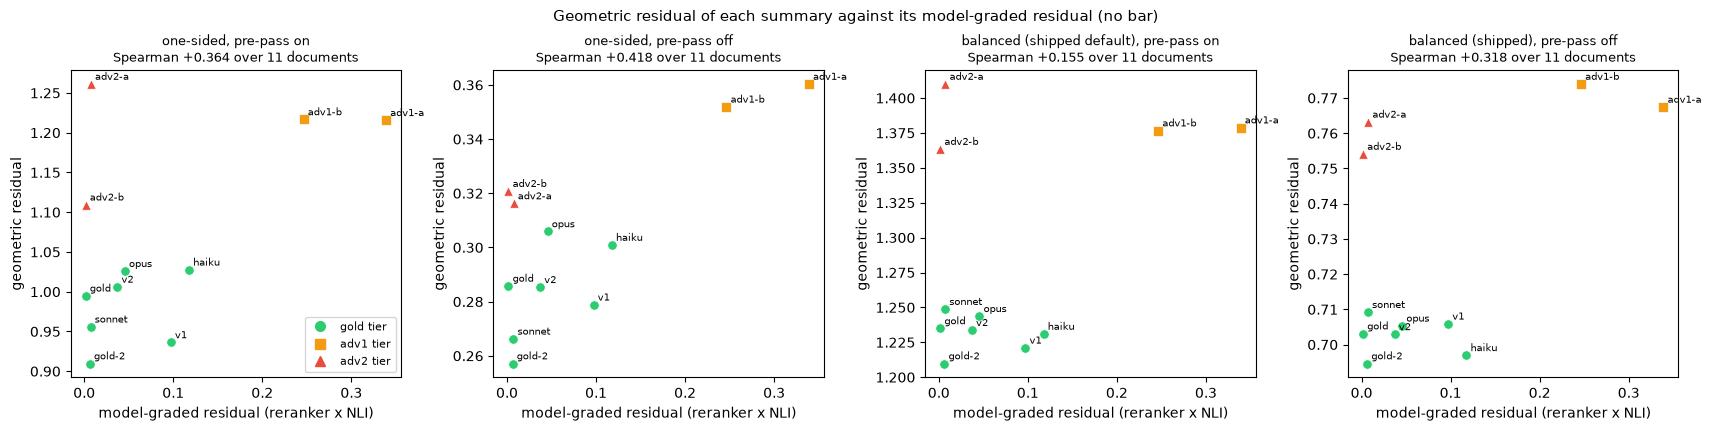

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for ax, arm in zip(axes, ARMS):
    for label in LABELS:
        ax.scatter(MODEL_GRD[label], NOBAR[arm]["residual"][label], color=TIER_COLOR[TIER[label]], s=46,
                   marker={"gold": "o", "adv1": "s", "adv2": "^"}[TIER[label]], edgecolor="white", linewidth=0.5)
        ax.annotate(label, (MODEL_GRD[label], NOBAR[arm]["residual"][label]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{ARMS[arm]}\nSpearman {NOBAR[arm]['spearman_vs_model_graded_documents']:+.3f} over 11 documents", fontsize=9)
    ax.set_xlabel("model-graded residual (reranker x NLI)"); ax.set_ylabel("geometric residual")
handles = [Line2D([], [], color=TIER_COLOR[t], marker=m, ls="", ms=7, label=f"{t} tier")
           for t, m in zip(TIERS, ("o", "s", "^"))]
axes[0].legend(handles=handles, fontsize=8)
fig.suptitle("Geometric residual of each summary against its model-graded residual (no bar)", fontsize=11)
plt.show()

**Reading** - no bar applies. All four arms place every gold-tier summary below both adv2 summaries; per statement, the one-sided residual on raw embeddings agrees best with the model-graded signal.

- **Tier means, one-sided, pre-pass off** - gold 0.2829, adv1 0.3561, adv2 0.3185. In none of the four arms does a gold-tier document read at or above the lowest adv2 document
- **adv1 reads above adv2 in three of the four arms** - the exception is balanced, pre-pass on (1.3777 against 1.3867). The model-graded residual also reads adv1 high (0.2927 against 0.0447 for gold), so the statements of the information-loss summaries are less supported by the source, and the tier is not only shorter
- **Geometry and the model-graded residual disagree on adv2** - the model-graded residual reads adv2 at 0.0045, below gold; every geometric arm reads adv2 above gold. E12-H69 measured the same near-zero adv2 reading of the shipped soft relevance gate
- **Rank agreement over the 11 documents** - Spearman +0.4182 (one-sided, pre-pass off), +0.3636 (one-sided, on), +0.3182 (balanced, off), +0.1545 (balanced, on). Eleven documents do not resolve differences of this size
- **Rank agreement over the 98 statements** - nearest-source cost against the per-statement ungrounded mass reads +0.6340 with the pre-pass off and +0.3972 with it on, the same order of the two arms as in the kill-gate

## Guardrails, measured

The standing guardrails of stage A, each one measured:

- **V** - ordinality violations of the naive panel (shipped `smd` against the anchor), counted before and after the arms
- **Default-path bit identity** - `smd`, `order_gap` and the three saved source-conditioned results, compared by `np.array_equal` before against after and against the saved 1.1.5 baseline
- **Harness setting** - shipped readings on one BLAS thread against the default thread count, by `np.array_equal`
- **Pre-pass replica** - `ungrounded_residual` on the replica's embeddings equals the shipped `residual_a`, exact float equality on every scored document
- **Metric property** - the lever is a score and a lower bound of the balanced residual; violations of one-sided $\le$ balanced are counted
- **No edit** - per-file byte digests of `src/`, `tests/` and `docs/` before against after, and `git status` on `src/` and `tests/`. The campaign orchestrator writes the ledger under `docs/` while executors run, so the `docs/` row is a reading and not part of the hold condition

In [20]:
limited = {
    "bal_pre": np.array([BASE[label]["bal_pre"] for label in LABELS] + [VERB["bal_pre"]]),
    "os_pre": np.array([BASE[label]["os_pre"] for label in LABELS] + [VERB["os_pre"]]),
}
BLAS_LIMIT.restore_original_limits()        # default BLAS thread count for every reading below

SNAP_AFTER = default_path_snapshot()
PANEL_AFTER = panel_metrics(SNAP_AFTER["smd"])
identical_before_after = {key: bool(np.array_equal(SNAP_BEFORE[key], SNAP_AFTER[key])) for key in SNAP_BEFORE}
saved_equal_after = {key: bool(np.array_equal(SNAP_AFTER[key], SAVED[key])) for key in SAVED}

check_docs = [E[label] for label in LABELS] + [X_V]
default_threads = {
    "bal_pre": np.array([compute_source_conditioned(X, X, E_S).residual_a for X in check_docs]),
    "os_pre": np.array([float(nearest_source_costs(*prepass(X, E_S)).mean()) for X in check_docs]),
}
thread_identical = {key: bool(np.array_equal(limited[key], default_threads[key])) for key in limited}

replica_exact = sum(1 for sc in SCORED if sc["replica_exact"])
bound_violations = sum(1 for sc in SCORED if sc["os_pre"] > sc["bal_pre"] or sc["os_raw"] > sc["bal_raw"])

DIGEST_AFTER = {folder: file_digests(folder) for folder in DIGEST_BEFORE}
files_changed = {folder: sorted(path for path in DIGEST_BEFORE[folder].keys() | DIGEST_AFTER[folder].keys()
                                if DIGEST_BEFORE[folder].get(path) != DIGEST_AFTER[folder].get(path))
                 for folder in DIGEST_BEFORE}
git_src_tests = subprocess.run(["git", "status", "--porcelain", "--", "src", "tests"], cwd=ROOT,
                               capture_output=True, text=True).stdout.strip()
src_untouched = not files_changed["src"] and not files_changed["tests"] and git_src_tests == ""

GUARD = {
    "V before the arms": (f"{PANEL_BEFORE['V']}/24", PANEL_BEFORE["V"] == 0),
    "V after the arms": (f"{PANEL_AFTER['V']}/24", PANEL_AFTER["V"] == 0),
    "smd, 10 anchor pairs, before == after (np.array_equal)": (str(identical_before_after["smd"]), identical_before_after["smd"]),
    "order_gap, 10 anchor pairs, before == after (np.array_equal)": (str(identical_before_after["order_gap"]), identical_before_after["order_gap"]),
    "source-conditioned, 3 saved pairs x 5 fields, before == after (np.array_equal)": (
        str(identical_before_after["source_conditioned"]), identical_before_after["source_conditioned"]),
    "smd == saved 1.1.5 baseline (np.array_equal)": (f"{saved_equal_before['smd']} / {saved_equal_after['smd']}",
                                                     saved_equal_before["smd"] and saved_equal_after["smd"]),
    "order_gap == saved 1.1.5 baseline (np.array_equal)": (f"{saved_equal_before['order_gap']} / {saved_equal_after['order_gap']}",
                                                           saved_equal_before["order_gap"] and saved_equal_after["order_gap"]),
    "source-conditioned == saved 1.1.5 baseline (np.array_equal)": (
        f"{saved_equal_before['source_conditioned']} / {saved_equal_after['source_conditioned']}",
        saved_equal_before["source_conditioned"] and saved_equal_after["source_conditioned"]),
    "pre-pass replica == shipped residual_a, exact, scored documents": (f"{replica_exact}/{len(SCORED)}", replica_exact == len(SCORED)),
    "one-sided > balanced (lower-bound violations), scored documents": (f"{bound_violations}/{len(SCORED)}", bound_violations == 0),
    "src/ files whose bytes changed during the run": (f"{len(files_changed['src'])}/{len(DIGEST_BEFORE['src'])}", not files_changed["src"]),
    "tests/ files whose bytes changed during the run": (f"{len(files_changed['tests'])}/{len(DIGEST_BEFORE['tests'])}", not files_changed["tests"]),
    "git status --porcelain -- src tests is empty": (str(git_src_tests == ""), git_src_tests == ""),
}
guardrails_hold = all(ok for _, ok in GUARD.values())

gr = Table(title="Guardrails - measured", header_style="bold cyan")
gr.add_column("guardrail"); gr.add_column("reading", justify="right"); gr.add_column("verdict")
for name, (reading, ok) in GUARD.items():
    gr.add_row(name, reading, "[green]holds[/green]" if ok else "[red]BREACH[/red]")
gr.add_row("docs/ files whose bytes changed during the run (other campaign processes write docs/)",
           f"{len(files_changed['docs'])}/{len(DIGEST_BEFORE['docs'])}", "reported")
gr.add_row("1 BLAS thread == default threads, balanced pre-pass on, 12 documents (np.array_equal)", str(thread_identical["bal_pre"]), "reported")
gr.add_row("1 BLAS thread == default threads, one-sided pre-pass on, 12 documents (np.array_equal)", str(thread_identical["os_pre"]), "reported")
panel_line = (f"naive panel after the arms: V {PANEL_AFTER['V']}/24, margin {PANEL_AFTER['margin_pts']:+.2f} pts, d' {PANEL_AFTER['dprime']:.2f}, "
              f"R {PANEL_AFTER['R']:.3f}, DR {PANEL_AFTER['DR']:.4f}")
docs_line = (f"docs/ files changed during the run: {files_changed['docs'] or 'none'}; "
             f"this notebook writes one file, {REPORT.relative_to(ROOT)}")
console.print(Group(gr, panel_line, docs_line,
                    f"[bold {'green' if guardrails_hold else 'red'}]GUARDRAILS: {'ALL HOLD' if guardrails_hold else 'BREACH'}[/]"))

                                               Guardrails - measured                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ guardrail                                                                              ┃     reading ┃ verdict  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ V before the arms                                                                      │        0/24 │ holds    │
│ V after the arms                                                                       │        0/24 │ holds    │
│ smd, 10 anchor pairs, before == after (np.array_equal)                                 │        True │ holds    │
│ order_gap, 10 anchor pairs, before == after (np.array_equal)                           │        True │ holds    │
│ source-conditioned, 3 saved pairs x 5 fields, before == after (np.array_equal)         │        True │ holds    │
│ smd == saved 1.1.5 baseline (np.array_equal)                                           │ True / True │ holds    │
│ order_gap == saved 1.1.5 baseline (np.array_equal)                                     │ True / True │ holds    │
│ source-conditioned == saved 1.1.5 baseline (np.array_equal)                            │ True / True │ holds    │
│ pre-pass replica == shipped residual_a, exact, scored documents                        │   1166/1166 │ holds    │
│ one-sided > balanced (lower-bound violations), scored documents                        │      0/1166 │ holds    │
│ src/ files whose bytes changed during the run                                          │        0/15 │ holds    │
│ tests/ files whose bytes changed during the run                                        │         0/9 │ holds    │
│ git status --porcelain -- src tests is empty                                           │        True │ holds    │
│ docs/ files whose bytes changed during the run (other campaign processes write docs/)  │        0/45 │ reported │
│ 1 BLAS thread == default threads, balanced pre-pass on, 12 documents (np.array_equal)  │        True │ reported │
│ 1 BLAS thread == default threads, one-sided pre-pass on, 12 documents (np.array_equal) │        True │ reported │
└────────────────────────────────────────────────────────────────────────────────────────┴─────────────┴──────────┘
naive panel after the arms: V 0/24, margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873
docs/ files changed during the run: none; this notebook writes one file, reports/E13-H73-nearest-source-residual-metrics.json
GUARDRAILS: ALL HOLD

**Reading** - every guardrail holds.

- **V** - 0/24 before and after the arms; the naive panel reads margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873, equal to the primer row
- **Default path** - `smd`, `order_gap` and the three source-conditioned results are bit-identical before and after the arms and equal to the saved 1.1.5 baseline
- **Same embeddings in both residuals** - the pre-pass replica equals the shipped `residual_a` exactly on 1166 of 1166 scored documents
- **Lower bound** - 0 of 1166 scored documents read a one-sided residual above the balanced residual of the same pre-pass setting
- **No edit** - no file under `src/` or `tests/` changed during the run and both folders are clean in git. This notebook writes one file, the metrics JSON under `reports/`. The `docs/` row counts files that another campaign process wrote during the run and the line under the table names them
- **Harness setting** - one BLAS thread and the default thread count give identical readings on the 12 checked documents

## Verdict against the registered bar

The verdict is read on the verdict arm fixed in the configuration. The order of the checks is the stage A order:
kill-gate, sanity check, guardrails, then the acceptance bar. A one-sided arm whose three bar readings all lie
within 0.01 of its balanced baseline is a null.

The prediction is checked twice, on both one-sided arms. **Magnitude** is the registered number: closeness at or
above 0.99, Spearman at or above 0.95, deletion ratio under 10%. **Direction** follows the configuration rule:
closeness above the balanced baseline of the same pre-pass setting, a median per-document Spearman above zero, and
no direction reading for the deletion effect, because the record registers a size for it and nothing else.
`direction_matched` over the three effects is true only when all three read matched. The deletion movement of each
one-sided arm is printed beside its balanced baseline on the same doses.

In [21]:
arm = VERDICT_ARM or VERDICT_ARM_ORDER[0]     # a fired gate still reports the default-call arm
base_arm = BASELINE_OF[arm]
b, bb = BAR[arm], BAR[base_arm]
bar_met = bool(b["met"])


def within_null(key: str) -> bool:
    '''True when the verdict arm and its balanced baseline differ by less than NULL_TOL on one bar reading'''
    return b[key] is not None and bb[key] is not None and abs(b[key] - bb[key]) < NULL_TOL


null_effect = all(within_null(key) for key in ("verbatim_closeness", "median_per_document_spearman", "deletion_ratio"))

if gate_killed:
    VERDICT = "Killed-at-gate"
elif not sanity_ok or not guardrails_hold:
    VERDICT = "Blocked"
elif bar_met:
    VERDICT = "Promoted"
elif null_effect:
    VERDICT = "Refuted (null)"
else:
    VERDICT = "Refuted"


def bar_text(a: str) -> str:
    '''The three bar readings of one arm, each with its status; the Spearman condition carries both readings'''
    x = BAR[a]
    status = {True: "met", False: "not met"}
    return (f"deletion ratio {share_text(x['deletion_ratio'])} (bar <= {BAR_DELETION_RATIO:.0%}, {status[x['deletion_ratio_met']]}); "
            f"verbatim-extract closeness {x['verbatim_closeness']:.4f} (bar >= {BAR_CLOSENESS}, {status[x['verbatim_closeness_met']]}); "
            f"median per-document Spearman {x['median_per_document_spearman']:.4f} (bar >= {BAR_SPEARMAN}, "
            f"{status[x['median_per_document_spearman_met']]} under the per-trajectory reading; "
            f"{INSERTION[a]['median_spearman_pooled_points']:.4f} under the pooled-points reading)")


other = next(a for a in ONE_SIDED if a != arm)
VERDICT_NUMBER = f"{ARMS[arm]} (kill-gate AUC {GATE[arm]['auc']:.4f}): {bar_text(arm)}"
OTHER_NUMBER = f"{ARMS[other]} (kill-gate AUC {GATE[other]['auc']:.4f}): {bar_text(other)}"
PREDICTED = ("verbatim extract 0.322 → >= 0.99", "Spearman(insertion dose, residual) >= 0.95",
             "deletions move it by under 10% of one insertion")


DIRECTION_TEXT = {True: "matched", False: "not matched", None: "not defined by the record"}
DIRECTION_STYLE = {True: "green", False: "red", None: "yellow"}


def prediction_check(a: str) -> dict:
    '''Per predicted effect of one one-sided arm: magnitude (the registered number) and direction (None = the record defines none)'''
    x, base = BAR[a], BAR[BASELINE_OF[a]]
    magnitude = (x["verbatim_closeness_met"], x["median_per_document_spearman_met"], x["deletion_ratio_met"])
    direction = (bool(x["verbatim_closeness"] > base["verbatim_closeness"]), bool(x["median_per_document_spearman"] > 0), None)
    return {text: {"magnitude_held": bool(m), "direction_matched": d} for text, m, d in zip(PREDICTED, magnitude, direction)}


def deletion_against_baseline(a: str) -> str:
    '''Median |residual change| under deletions of a one-sided arm beside its balanced baseline on the same doses'''
    lever, base = DELETION[a]["median_abs_delta"], DELETION[BASELINE_OF[a]]["median_abs_delta"]
    return (f"{ARMS[a]}: median |delta| under deletions {lever:.6f} against {base:.6f} for {ARMS[BASELINE_OF[a]]}, "
            f"{'below' if lever < base else 'not below'} the baseline")


PREDICTION = {a: prediction_check(a) for a in ONE_SIDED}
direction_matched = all(v["direction_matched"] is True for v in PREDICTION[arm].values())   # None is not a match
magnitude_held = all(v["magnitude_held"] for v in PREDICTION[arm].values())
DIRECTION_SUMMARY = "; ".join(f"({n}) {DIRECTION_TEXT[v['direction_matched']]}"
                              for n, v in zip(("i", "ii", "iii"), PREDICTION[arm].values()))

pc = Table(title="Prediction check - direction and magnitude, both one-sided arms", header_style="bold cyan")
pc.add_column("predicted")
for a in ONE_SIDED:
    pc.add_column(f"{ARMS[a]}{' (verdict arm)' if a == arm else ''}: direction"); pc.add_column("magnitude")
for text in PREDICTED:
    cells = []
    for a in ONE_SIDED:
        v = PREDICTION[a][text]
        cells.append(f"[{DIRECTION_STYLE[v['direction_matched']]}]{DIRECTION_TEXT[v['direction_matched']]}[/]")
        cells.append("[green]held[/green]" if v["magnitude_held"] else "[red]falsified[/red]")
    pc.add_row(text, *cells)

colour = {"Promoted": "green", "Confirmed": "green"}.get(VERDICT, "red")
console.print(Group(pc, *[deletion_against_baseline(a) for a in ONE_SIDED], Panel(
    f"[bold {colour}]{VERDICT}[/]\n{VERDICT_NUMBER}\n{OTHER_NUMBER}\n"
    f"kill-gate passed: {not gate_killed} | sanity check passed: {sanity_ok} | guardrails hold: {guardrails_hold} | "
    f"bar met on the verdict arm: {bar_met}\n"
    f"prediction on the verdict arm, direction: {DIRECTION_SUMMARY} | direction matched on all three effects: "
    f"{direction_matched} | magnitude held on all three: {magnitude_held}",
    title="E13-H73 verdict", border_style=colour)))

                                                 Prediction check - direction and magnitude, both one-sided arms                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ predicted                                       ┃ one-sided, pre-pass on: direction ┃ magnitude ┃ one-sided, pre-pass off (verdict arm): direction ┃ magnitude ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ verbatim extract 0.322 → >= 0.99                │ matched                           │ held      │ matched                                          │ held      │
│ Spearman(insertion dose, residual) >= 0.95      │ matched                           │ held      │ matched                                          │ held      │
│ deletions move it by under 10% of one insertion │ not defined by the record         │ falsified │ not defined by the record                        │ falsified │
└─────────────────────────────────────────────────┴───────────────────────────────────┴───────────┴──────────────────────────────────────────────────┴───────────┘
one-sided, pre-pass on: median |delta| under deletions 0.023256 against 0.015477 for balanced (shipped default), pre-pass on, not below the baseline
one-sided, pre-pass off: median |delta| under deletions 0.005211 against 0.005043 for balanced (shipped), pre-pass off, not below the baseline
╭──────────────────────────────────────────────────────────────────────────────── E13-H73 verdict ─────────────────────────────────────────────────────────────────────────────────╮
│ Refuted                                                                                                                                                                          │
│ one-sided, pre-pass off (kill-gate AUC 0.9670): deletion ratio 34.1% (bar <= 10%, not met); verbatim-extract closeness 0.9999 (bar >= 0.99, met); median per-document Spearman   │
│ 1.0000 (bar >= 0.95, met under the per-trajectory reading; 0.9492 under the pooled-points reading)                                                                               │
│ one-sided, pre-pass on (kill-gate AUC 0.7889): deletion ratio 310.4% (bar <= 10%, not met); verbatim-extract closeness 0.9999 (bar >= 0.99, met); median per-document Spearman   │
│ 0.9643 (bar >= 0.95, met under the per-trajectory reading; 0.8674 under the pooled-points reading)                                                                               │
│ kill-gate passed: True | sanity check passed: True | guardrails hold: True | bar met on the verdict arm: False                                                                   │
│ prediction on the verdict arm, direction: (i) matched; (ii) matched; (iii) not defined by the record | direction matched on all three effects: False | magnitude held on all     │
│ three: False                                                                                                                                                                     │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, the bar readings and the guardrail readings are written to
`reports/E13-H73-nearest-source-residual-metrics.json` and printed below. The `result` block follows the stage A
return schema.

In [22]:
def r6(value):
    '''Round to 6 decimals for the JSON; None stays None'''
    return None if value is None else round(float(value), 6)


def arm_block(a: str) -> dict:
    '''Every reading of one arm, rounded for the JSON'''
    return {
        "label": ARMS[a],
        "verbatim": {key: r6(value) for key, value in VERBATIM[a].items()},
        "insertion": {
            "one_insertion_effect": r6(INSERTION[a]["one_insertion_effect"]),
            "mean_residual_by_k": [r6(v) for v in INSERTION[a]["mean_residual_by_k"]],
            "median_per_document_spearman": r6(INSERTION[a]["median_per_document_spearman"]),
            "min_per_document_spearman": r6(INSERTION[a]["min_per_document_spearman"]),
            "per_document_spearman": {l: r6(v) for l, v in INSERTION[a]["per_document_spearman"].items()},
            "monotone_trajectory_share": r6(INSERTION[a]["monotone_trajectory_share"]),
            "median_spearman_pooled_points": r6(INSERTION[a]["median_spearman_pooled_points"]),
            "median_spearman_seed_mean_curve": r6(INSERTION[a]["median_spearman_seed_mean_curve"]),
        },
        "deletion": {
            "median_abs_delta": r6(DELETION[a]["median_abs_delta"]),
            "ratio_to_one_insertion": r6(DELETION[a]["ratio_to_one_insertion"]),
            "mean_signed_delta": r6(DELETION[a]["mean_signed_delta"]),
            "mean_signed_delta_share": r6(DELETION[a]["mean_signed_delta_share"]),
            "ratio_k1_only": r6(DELETION[a]["ratio_k1_only"]),
            "ratio_matched_documents": r6(DELETION[a]["ratio_matched_documents"]),
            "n_documents_with_deletion_doses": DELETION[a]["n_documents_with_deletion_doses"],
            "median_abs_delta_by_k": [r6(v) for v in DELETION[a]["median_abs_delta_by_k"]],
            "p90_abs_delta": r6(DELETION[a]["p90_abs_delta"]),
        },
        "bar": {"verbatim_closeness_met": BAR[a]["verbatim_closeness_met"],
                "median_per_document_spearman_met": BAR[a]["median_per_document_spearman_met"],
                "deletion_ratio_met": BAR[a]["deletion_ratio_met"], "met": BAR[a]["met"]},
        "no_bar": {
            "residual_by_document": {l: r6(v) for l, v in NOBAR[a]["residual"].items()},
            "tier_mean": {t: r6(v) for t, v in NOBAR[a]["tier_mean"].items()},
            "gold_at_or_above_lowest_adv2": NOBAR[a]["gold_at_or_above_lowest_adv2"],
            "spearman_vs_model_graded_documents": r6(NOBAR[a]["spearman_vs_model_graded_documents"]),
            "spearman_vs_ungrounded_mass_statements": r6(NOBAR[a].get("spearman_vs_ungrounded_mass_statements")),
        },
    }


gate_reading = ("statement-level AUC of nearest-source cost, own vs foreign, "
                + "; ".join(f"{ARMS[a]}: {GATE[a]['auc']:.4f} ({'pass' if GATE[a]['passed'] else 'fail'})" for a in ONE_SIDED)
                + f" (bar >= {GATE_AUC_MIN}; {N_OWN} own x {int(PROSE.sum())} foreign = {N_PAIRS} pairs). The record names no "
                "pre-pass setting for the gate; the notebook's rule kills only when both settings read below the bar; "
                f"settings that pass: {', '.join(ARMS[a] for a in ONE_SIDED if GATE[a]['passed']) or 'none'}")
sanity_reading = (f"DEF-TRANS-8 on source[0::7][:10], shipped compute_source_conditioned, pre-pass on: residual_a "
                  f"{sanity_read['residual_a']:.3f} (registered 0.958), closeness_a {sanity_read['closeness_a']:.3f} (registered 0.322); "
                  f"pre-pass off: residual_a {shipped_off.residual_a:.3f}, closeness_a {shipped_off.closeness_a:.3f}")
RESULT = {
    "id": "E13-H73", "slug": "nearest-source-residual", "model": "opus",
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
    "kill_gate": {"ran": True, "passed": not gate_killed, "reading": gate_reading},
    "sanity_check": {"required": True, "passed": bool(sanity_ok), "reading": sanity_reading},
    "prediction_check": {
        "predicted": "verbatim extract 0.322 → >= 0.99; Spearman(insertion dose, residual) >= 0.95; "
                     "deletions move it by under 10% of one insertion",
        "observed": (f"{VERDICT_NUMBER} | {OTHER_NUMBER} | direction on the verdict arm: {DIRECTION_SUMMARY}; "
                     f"{deletion_against_baseline(arm)} | direction matched on all three predicted effects: "
                     f"{direction_matched}; the registered magnitude of all three held: {magnitude_held}"),
        "direction_matched": bool(direction_matched),
    },
    "acceptance": {
        "bar": "PASS iff verbatim-extract closeness >= 0.99 AND median per-document Spearman(k foreign insertions, residual) "
               ">= 0.95 over k in 0..4 AND median |delta residual| under k in 1..4 deletions <= 10% of the mean one-insertion effect",
        "met": bar_met,
        "readings": {a: {"label": ARMS[a], "verbatim_closeness": r6(BAR[a]["verbatim_closeness"]),
                         "median_per_document_spearman": r6(BAR[a]["median_per_document_spearman"]),
                         "median_spearman_pooled_points_not_the_bar_rule": r6(INSERTION[a]["median_spearman_pooled_points"]),
                         "deletion_ratio": r6(BAR[a]["deletion_ratio"]), "met": BAR[a]["met"]} for a in ARMS},
    },
    "guardrails": {
        "V": f"{PANEL_AFTER['V']}/24",
        "src_untouched": bool(src_untouched),
        "metric_property": "untouched: shipped smd, order_gap and source-conditioned outputs bit-identical before and after and "
                           "equal to the saved 1.1.5 baseline; the one-sided residual is a score and a lower bound of the "
                           f"balanced residual ({bound_violations} violations in {len(SCORED)} scored documents), not a metric",
        "notes": f"pre-pass replica equals the shipped residual_a exactly on {replica_exact}/{len(SCORED)} scored documents; "
                 f"BLAS limited to 1 thread for the arms, readings identical to the default thread count: "
                 f"balanced {thread_identical['bal_pre']}, one-sided {thread_identical['os_pre']}; files changed during the run: "
                 f"src/ {len(files_changed['src'])}, tests/ {len(files_changed['tests'])}, docs/ {len(files_changed['docs'])} "
                 f"(this notebook writes only the metrics JSON under reports/)",
    },
    "key_numbers": {
        "verdict_arm": arm,
        "gate_auc": {a: r6(GATE[a]["auc"]) for a in ONE_SIDED},
        "def_trans_8": {"residual_a": r6(sanity_read["residual_a"]), "closeness_a": r6(sanity_read["closeness_a"])},
        "verbatim_closeness": {a: r6(BAR[a]["verbatim_closeness"]) for a in ARMS},
        "median_per_document_spearman": {a: r6(BAR[a]["median_per_document_spearman"]) for a in ARMS},
        "median_spearman_pooled_points": {a: r6(INSERTION[a]["median_spearman_pooled_points"]) for a in ARMS},
        "pooled_points_spearman_ceiling": r6(POOLED_CEILING),
        "deletion_ratio": {a: r6(BAR[a]["deletion_ratio"]) for a in ARMS},
        "deletion_ratio_k1_only": {a: r6(DELETION[a]["ratio_k1_only"]) for a in ARMS},
        "deletion_ratio_matched_documents": {a: r6(DELETION[a]["ratio_matched_documents"]) for a in ARMS},
        "p90_abs_delta_deletion": {a: r6(DELETION[a]["p90_abs_delta"]) for a in ARMS},
        "direction_by_effect": {text: v["direction_matched"] for text, v in PREDICTION[arm].items()},
        "one_insertion_effect": {a: r6(INSERTION[a]["one_insertion_effect"]) for a in ARMS},
        "median_abs_delta_deletion": {a: r6(DELETION[a]["median_abs_delta"]) for a in ARMS},
        "mean_signed_delta_deletion": {a: r6(DELETION[a]["mean_signed_delta"]) for a in ARMS},
        "mean_signed_delta_share": {a: r6(DELETION[a]["mean_signed_delta_share"]) for a in ARMS},
        "min_per_document_spearman": {a: r6(INSERTION[a]["min_per_document_spearman"]) for a in ARMS},
        "tier_mean": {a: {t: r6(v) for t, v in NOBAR[a]["tier_mean"].items()} for a in ARMS},
        "spearman_vs_model_graded_documents": {a: r6(NOBAR[a]["spearman_vs_model_graded_documents"]) for a in ARMS},
    },
    "artifacts": {
        "notebook": "notebooks/experiments/E13-H73-kj-nearest-source-residual.ipynb",
        "metrics_json": "reports/E13-H73-nearest-source-residual-metrics.json",
        "log": "logs/E13-H73-nearest-source-residual.log",
    },
}

payload = {
    "id": "E13-H73", "slug": "nearest-source-residual", "model": "opus",
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER, "other_arm_number": OTHER_NUMBER, "verdict_arm": arm,
    "environment": {"python": sys.version.split()[0], "docdistance": docdistance.__version__, "pot": ot.__version__,
                    "numpy": np.__version__, "uptime_at_start": uptime, "blas_threads_for_arms": 1},
    "fixture": {
        "n_source_statements": len(E_S), "n_own_statements": N_OWN,
        "statements_by_document": {label: len(E[label]) for label in LABELS},
        "n_wergeland_fragments": len(E_W), "n_foreign_statements": int(PROSE.sum()), "min_foreign_words": MIN_FOREIGN_WORDS,
        "fingerprint_matches_e12_h69": bool(fingerprint_match),
        "n_seeds": N_SEEDS, "seed": SEED, "insert_ks": list(INSERT_KS), "delete_ks": list(DELETE_KS),
        "n_inserted_documents_scored": n_insert_scored, "n_deletion_cases": n_delete_cases, "n_scored_documents": len(SCORED),
        "pooled_points_spearman_ceiling": r6(POOLED_CEILING),
    },
    "kill_gate": {
        "bar": GATE_AUC_MIN, "killed": bool(gate_killed), "n_pairs": N_PAIRS,
        "arms": {a: {"label": ARMS[a], **{key: (bool(v) if key == "passed" else r6(v)) for key, v in GATE[a].items()}} for a in ONE_SIDED},
    },
    "sanity_check": {
        "passed": bool(sanity_ok), "target": SANITY_TARGET,
        "balanced_prepass_on": {"residual_a": r6(shipped_on.residual_a), "closeness_a": r6(shipped_on.closeness_a)},
        "balanced_prepass_off": {"residual_a": r6(shipped_off.residual_a), "closeness_a": r6(shipped_off.closeness_a)},
        "nearest_source_mean_cost": {"prepass_on": r6(nearest_pre), "prepass_off": r6(nearest_raw)},
        "mass_kept_on_own_copy": {"max": r6(kept.max()), "mean": r6(kept.mean()), "bound_n_over_m": r6(mass_bound)},
    },
    "arms": {a: arm_block(a) for a in ARMS},
    "model_graded_residual": {label: r6(MODEL_GRD[label]) for label in LABELS},
    "guardrails": {
        "hold": bool(guardrails_hold),
        "readings": {name: {"reading": reading, "ok": bool(ok)} for name, (reading, ok) in GUARD.items()},
        "panel_before": {key: r6(v) for key, v in PANEL_BEFORE.items()},
        "panel_after": {key: r6(v) for key, v in PANEL_AFTER.items()},
        "files_changed_during_run": files_changed,
        "blas_1_thread_equals_default": thread_identical,
    },
    "prediction_check": PREDICTION,
    "result": RESULT,
}
REPORT.write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"wrote {REPORT.relative_to(ROOT)} ({REPORT.stat().st_size} bytes)")
print(json.dumps(payload, indent=1, ensure_ascii=False))

wrote reports/E13-H73-nearest-source-residual-metrics.json (23575 bytes)
{
 "id": "E13-H73",
 "slug": "nearest-source-residual",
 "model": "opus",
 "verdict": "Refuted",
 "verdict_number": "one-sided, pre-pass off (kill-gate AUC 0.9670): deletion ratio 34.1% (bar <= 10%, not met); verbatim-extract closeness 0.9999 (bar >= 0.99, met); median per-document Spearman 1.0000 (bar >= 0.95, met under the per-trajectory reading; 0.9492 under the pooled-points reading)",
 "other_arm_number": "one-sided, pre-pass on (kill-gate AUC 0.7889): deletion ratio 310.4% (bar <= 10%, not met); verbatim-extract closeness 0.9999 (bar >= 0.99, met); median per-document Spearman 0.9643 (bar >= 0.95, met under the per-trajectory reading; 0.8674 under the pooled-points reading)",
 "verdict_arm": "os_raw",
 "environment": {
  "python": "3.14.8",
  "docdistance": "1.1.5",
  "pot": "0.9.6.post1",
  "numpy": "2.4.6",
  "uptime_at_start": "11:47:46 up 1 day, 13:08,  0 user,  load average: 43.52, 47.97, 44.20",
  "bla

## Conclusions

**Verdict: Refuted.** The registered bar joins three conditions with AND, and the third is not met: under deletions the one-sided residual moves by a median of 34.1% of one insertion (pre-pass off), against a bar of 10%. Of the other two conditions, (i) is met by construction and (ii) is met under the configured reading rule and not under the pooled-points reading.

- **Kill-gate** - passed on the raw embeddings (AUC 0.9670) and not passed with the pre-pass on (AUC 0.7889). Under the rule fixed in the configuration the gate does not fire and the verdict is read on the pre-pass-off arm. Under the alternative rule that reads the gate on the default call only, the outcome is `Killed-at-gate`; both rules end without a promotion. The record names no pre-pass setting for the gate, so the choice between the two rules is the campaign orchestrator's
- **Sanity check** - `DEF-TRANS-8` reproduced: `residual_a` 0.958, `closeness_a` 0.322; each copied statement keeps 0.142857 = `n/m` of its mass on its own copy
- **Condition (i), met by construction** - verbatim-extract closeness 0.3224 → 0.9999 with the pre-pass on and 0.6343 → 0.9999 with it off. A copied statement has nearest-source cost zero in any residual with the source marginal released, so this condition cannot fail for the lever
- **Condition (ii), met under the per-trajectory reading** - median per-document Spearman 1.0000 (pre-pass off) and 0.9643 (pre-pass on). Under the pooled-points reading the same doses read 0.9492 and 0.8674, below the 0.95 bar. On the same doses the shipped balanced residual reads -0.2571 and -0.8429: it falls when foreign statements are added
- **Condition (iii), not met** - deletion ratio 34.1% (pre-pass off) and 310.4% (pre-pass on), against 10%. The one-sided residual does not move less under deletions than the balanced baseline on the same doses: median |change| 0.00521 against 0.00504 (pre-pass off) and 0.02326 against 0.01548 (pre-pass on)
- **Prediction** - the registered size held on (i) and (ii) and was falsified on (iii). The direction matched on (i) and (ii). The record defines no direction for (iii), so the direction of the three effects together is reported as not matched
- **Guardrails** - V 0/24, default path bit-identical and equal to the saved 1.1.5 baseline, no file changed under `src/` or `tests/`; the metrics JSON is the only file this notebook writes

**Mechanism** - with the source marginal released, each statement ships its whole mass to its nearest source statement. This removes the `n/m` bound that produces `DEF-TRANS-8` and changes the sign of the insertion response from negative to positive. The same change makes the residual the mean of per-statement costs, and a mean moves when a statement above or below it is removed. The size of that move against one insertion is set by the spread of the own costs (0.0532) against the gap to the foreign costs (0.1197); the registered 10% ratio needs a spread close to one tenth of the gap.

**Meaning** - the lever removes the `n/m` bound that produces `DEF-TRANS-8`, and it rises with foreign content where the balanced residual falls. Of the three bar conditions, one could have failed and was met: the insertion response, under the configured reading rule. The flat response under deletions that the hypothesis states does not hold: per case the one-sided residual moves as much as the balanced residual (0.00521 against 0.00504). With the pre-pass off its signed change is -0.7% of one insertion on average, while the balanced residual rises by +0.00622.

**Impact on the default call** - `compute_source_conditioned` applies the pre-pass by default. Inside that call the nearest-source cost separates own from foreign statements at AUC 0.7889, below the 0.90 gate; the deletion ratio is 310.4%; the one-statement document `adv2-a` reads a dose-response of -0.4786. On the raw embeddings the same residual reads AUC 0.9670 and a deletion ratio of 34.1%.

**Limitations**

- One source article and one foreign article; the foreign set is 38 statements from an article on a related topic
- 11 summaries, of which two have 1 and 3 statements; `adv2-a` has no deletion dose
- The pre-pass arms use the pool of `compute_source_conditioned(X, X, S)`. In a call with two different documents the pre-pass pools both, so the residual of one document depends on the other
- Three reading rules are the executor's because the record does not state them: the gate over two pre-pass settings, the per-document Spearman, the foreign set. The notebook was executed more than once, so its outputs do not prove that each rule was written before the first numbers were seen. Each rule has a second reading above: the gate on the default call (0.7889, fires), the pooled-points Spearman (0.9492 and 0.8674), all 44 wergeland fragments (AUC 0.9260 and 0.7270)
- Condition (i) uses statements copied verbatim; an extract that paraphrases the source was not measured
- The loss of AUC under the pre-pass was not decomposed into the mean subtraction and the component removal